# Resource Check

In [1]:

# ============================================================
# B1 — CELL 1: ENVIRONMENT AND GPU VERIFICATION
# Model: Microsoft LLaVA-Med v1.5 Mistral-7B
# Dataset: Official SLAKE 1.0 test split
# Retention: 100%, 75%, 50%, 25%
# ============================================================

import os
import sys
import json
import platform
import subprocess
from pathlib import Path

import torch

print("=" * 70)
print("B1 — ENVIRONMENT VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Runtime
# ------------------------------------------------------------
print("\n[1] RUNTIME")
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

# ------------------------------------------------------------
# 2. GPU
# ------------------------------------------------------------
print("\n[2] GPU INFORMATION")

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU not detected. Enable GPU in Kaggle settings."
    )

gpu_count = torch.cuda.device_count()
print("GPU count:", gpu_count)

for i in range(gpu_count):
    props = torch.cuda.get_device_properties(i)
    print(f"\nGPU {i}: {props.name}")
    print(f"Total VRAM: {props.total_memory / 1024**3:.2f} GiB")
    print("Compute capability:", 
          f"{props.major}.{props.minor}")

# ------------------------------------------------------------
# 3. GPU utilization
# ------------------------------------------------------------
print("\n[3] NVIDIA-SMI")

result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

print(result.stdout if result.returncode == 0
      else result.stderr)

# ------------------------------------------------------------
# 4. Package versions (no installations yet)
# ------------------------------------------------------------
print("\n[4] LIBRARY VERSIONS")

from importlib.metadata import version, PackageNotFoundError

packages = [
    "transformers",
    "accelerate",
    "tokenizers",
    "safetensors",
    "huggingface_hub",
    "bitsandbytes",
    "sentencepiece",
    "numpy",
    "pandas",
    "Pillow",
]

for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

# ------------------------------------------------------------
# 5. Kaggle input datasets
# ------------------------------------------------------------
print("\n[5] KAGGLE INPUT DIRECTORIES")

input_root = Path("/kaggle/input")

if input_root.exists():
    datasets = sorted(input_root.iterdir())

    if datasets:
        for path in datasets:
            print(path)
    else:
        print("No datasets attached yet.")
else:
    print("Kaggle input directory not found.")

# ------------------------------------------------------------
# 6. Create B1-specific output directories
# ------------------------------------------------------------
print("\n[6] EXPERIMENT DIRECTORIES")

B1_ROOT = Path("/kaggle/working/B1_LLaVA_Med")

for folder in [
    "configs",
    "manifests",
    "predictions",
    "metrics",
    "profiling",
    "logs"
]:
    path = B1_ROOT / folder
    path.mkdir(parents=True, exist_ok=True)
    print("Ready:", path)

# ------------------------------------------------------------
# 7. Baseline configuration
# ------------------------------------------------------------
B1_CONFIG = {
    "experiment": "B1",
    "model": "microsoft/llava-med-v1.5-mistral-7b",
    "dataset": "SLAKE 1.0",
    "split": "official_test",
    "language": "en",
    "retention_rates": [1.00, 0.75, 0.50, 0.25],
    "temperature": 0.0,
    "batch_size": 1,
    "seed": 42,
    "metrics": {
        "closed": ["accuracy"],
        "open": ["recall", "f1"],
        "performance": [
            "prefill_time_ms",
            "total_time_ms",
            "peak_gpu_memory_gib"
        ]
    }
}

config_path = B1_ROOT / "configs" / "b1_config.json"

with open(config_path, "w") as f:
    json.dump(B1_CONFIG, f, indent=2)

print("\nConfiguration saved:", config_path)

# ------------------------------------------------------------
# 8. Final sanity checks
# ------------------------------------------------------------
assert torch.cuda.is_available()
assert len(B1_CONFIG["retention_rates"]) == 4
assert B1_CONFIG["split"] == "official_test"
assert B1_CONFIG["batch_size"] == 1

print("\n" + "=" * 70)
print("CELL 1 PASSED — GPU AND B1 ENVIRONMENT VERIFIED")
print("=" * 70)


B1 — ENVIRONMENT VERIFICATION

[1] RUNTIME
Python: 3.13.15
Platform: Linux-6.18.48+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu128
CUDA build: 12.8
CUDA available: True

[2] GPU INFORMATION
GPU count: 2

GPU 0: Tesla T4
Total VRAM: 14.56 GiB
Compute capability: 7.5

GPU 1: Tesla T4
Total VRAM: 14.56 GiB
Compute capability: 7.5

[3] NVIDIA-SMI
Fri Oct 16 18:38:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======

# Llava-med repo Clone

In [2]:

# ============================================================
# B1 — CELL 2: OFFICIAL LLAVA-MED SOURCE VERIFICATION
# ============================================================

import sys
import shutil
import subprocess
from pathlib import Path
from importlib.metadata import version

REPO_URL = "https://github.com/microsoft/LLaVA-Med.git"
REPO_DIR = Path("/kaggle/working/LLaVA-Med")
B1_ROOT = Path("/kaggle/working/B1_LLaVA_Med")

print("=" * 70)
print("B1 — OFFICIAL SOURCE VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Clone official repository
# ------------------------------------------------------------
print("\n[1] OFFICIAL REPOSITORY")

if not (REPO_DIR / ".git").exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )
else:
    print("Repository already cloned.")

# ------------------------------------------------------------
# 2. Record exact commit
# ------------------------------------------------------------
print("\n[2] SOURCE VERSION")

commit = subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"],
    text=True
).strip()

print("Repository:", REPO_URL)
print("Commit:", commit)

# ------------------------------------------------------------
# 3. Required files
# ------------------------------------------------------------
print("\n[3] REQUIRED FILES")

required_files = [
    "pyproject.toml",
    "llava/model/builder.py",
    "llava/model/llava_arch.py",
    "llava/eval/model_vqa.py",
    "llava/conversation.py",
]

for name in required_files:
    path = REPO_DIR / name
    print(f"{name}: {'FOUND' if path.is_file() else 'MISSING'}")
    assert path.is_file(), f"Missing official file: {name}"

# ------------------------------------------------------------
# 4. Official dependency declarations
# ------------------------------------------------------------
print("\n[4] OFFICIAL DEPENDENCY PINS")

import tomllib

with open(REPO_DIR / "pyproject.toml", "rb") as f:
    project = tomllib.load(f)

dependencies = project["project"]["dependencies"]

for keyword in [
    "transformers",
    "tokenizers",
    "accelerate",
    "peft",
    "bitsandbytes",
    "sentencepiece",
    "numpy",
    "pydantic"
]:
    matches = [
        dep for dep in dependencies
        if dep.lower().startswith(keyword)
    ]
    print(f"{keyword}: {matches[0] if matches else 'NOT PINNED'}")

# ------------------------------------------------------------
# 5. Python environment options
# ------------------------------------------------------------
print("\n[5] PYTHON ENVIRONMENT OPTIONS")

print("Current Python:", sys.version.split()[0])
print("Current executable:", sys.executable)

for executable in ["python3.10", "python3.11", "uv", "conda"]:
    path = shutil.which(executable)
    print(f"{executable}: {path if path else 'NOT FOUND'}")

# ------------------------------------------------------------
# 6. Save source identity
# ------------------------------------------------------------
import json

source_info = {
    "repository": REPO_URL,
    "commit": commit,
    "model_id": "microsoft/llava-med-v1.5-mistral-7b",
    "python_runtime": sys.version.split()[0],
    "installation_complete": False
}

output = B1_ROOT / "configs" / "source_version.json"
output.parent.mkdir(parents=True, exist_ok=True)

with open(output, "w") as f:
    json.dump(source_info, f, indent=2)

print("\nSource metadata:", output)

print("\n" + "=" * 70)
print("CELL 2 PASSED — OFFICIAL SOURCE VERIFIED")
print("=" * 70)


B1 — OFFICIAL SOURCE VERIFICATION

[1] OFFICIAL REPOSITORY


Cloning into '/kaggle/working/LLaVA-Med'...



[2] SOURCE VERSION
Repository: https://github.com/microsoft/LLaVA-Med.git
Commit: 30697ca50b5c29a8e955c99330b259776aef27b9

[3] REQUIRED FILES
pyproject.toml: FOUND
llava/model/builder.py: FOUND
llava/model/llava_arch.py: FOUND
llava/eval/model_vqa.py: FOUND
llava/conversation.py: FOUND

[4] OFFICIAL DEPENDENCY PINS
transformers: transformers==4.36.2
tokenizers: tokenizers>=0.15.0
accelerate: accelerate==0.21.0
peft: peft==0.4.0
bitsandbytes: bitsandbytes==0.41.0
sentencepiece: sentencepiece==0.1.99
numpy: numpy
pydantic: pydantic<2,>=1

[5] PYTHON ENVIRONMENT OPTIONS
Current Python: 3.13.15
Current executable: /usr/bin/python3
python3.10: NOT FOUND
python3.11: NOT FOUND
uv: /usr/local/bin/uv
conda: NOT FOUND

Source metadata: /kaggle/working/B1_LLaVA_Med/configs/source_version.json

CELL 2 PASSED — OFFICIAL SOURCE VERIFIED


In [3]:

# ============================================================
# B1 — CELL 3: CREATE ISOLATED PYTHON 3.10 ENVIRONMENT
# ============================================================

import subprocess
from pathlib import Path

B1_ROOT = Path("/kaggle/working/B1_LLaVA_Med")
ENV_DIR = B1_ROOT / "venv"
PYTHON_EXE = ENV_DIR / "bin" / "python"

print("=" * 70)
print("B1 — PYTHON 3.10 ENVIRONMENT SETUP")
print("=" * 70)

# Check uv
subprocess.run(["uv", "--version"], check=True)

# Install managed Python 3.10
print("\n[1] INSTALL PYTHON 3.10")

subprocess.run(
    ["uv", "python", "install", "3.10"],
    check=True
)

# Create isolated environment
print("\n[2] CREATE VIRTUAL ENVIRONMENT")

if not PYTHON_EXE.exists():
    subprocess.run(
        [
            "uv", "venv",
            "--python", "3.10",
            str(ENV_DIR)
        ],
        check=True
    )
else:
    print("Existing environment found.")

# Verify environment
print("\n[3] VERIFY PYTHON VERSION")

result = subprocess.run(
    [
        str(PYTHON_EXE),
        "-c",
        "import sys; print(sys.version); print(sys.executable)"
    ],
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout)

# Confirm version
version_result = subprocess.check_output(
    [
        str(PYTHON_EXE),
        "-c",
        "import sys; print(sys.version_info[:2])"
    ],
    text=True
).strip()

assert version_result == "(3, 10)", (
    f"Expected Python 3.10, got {version_result}"
)

print("\n" + "=" * 70)
print("CELL 3 PASSED — PYTHON 3.10 ENVIRONMENT READY")
print("=" * 70)


B1 — PYTHON 3.10 ENVIRONMENT SETUP
uv 0.12.9 (x86_64-unknown-linux-gnu)

[1] INSTALL PYTHON 3.10


Installed Python 3.10.21 in 1.35s
 + cpython-3.10.21-linux-x86_64-gnu (python3.10)



[2] CREATE VIRTUAL ENVIRONMENT

[3] VERIFY PYTHON VERSION
3.10.21 (main, Sep  1 2026, 14:16:49) [Clang 22.1.3 ]
/kaggle/working/B1_LLaVA_Med/venv/bin/python


CELL 3 PASSED — PYTHON 3.10 ENVIRONMENT READY


Using CPython 3.10.21
Creating virtual environment at: B1_LLaVA_Med/venv
Activate with: source B1_LLaVA_Med/venv/bin/activate


In [4]:

# ============================================================
# B1 — CELL 4: INSTALL OFFICIAL INFERENCE DEPENDENCIES
# ============================================================

import subprocess
from pathlib import Path

B1_ROOT = Path("/kaggle/working/B1_LLaVA_Med")
REPO_DIR = Path("/kaggle/working/LLaVA-Med")
PYTHON_EXE = B1_ROOT / "venv/bin/python"

assert PYTHON_EXE.exists()
assert (REPO_DIR / "pyproject.toml").exists()

print("=" * 70)
print("B1 — LLAVA-MED DEPENDENCY INSTALLATION")
print("=" * 70)

def install(packages, extra_args=None):
    command = [
        "uv", "pip", "install",
        "--python", str(PYTHON_EXE)
    ]

    if extra_args:
        command.extend(extra_args)

    command.extend(packages)

    subprocess.run(command, check=True)

# ------------------------------------------------------------
# 1. CUDA-enabled PyTorch
# ------------------------------------------------------------
print("\n[1] INSTALL PYTORCH + CUDA 12.1 RUNTIME")

install(
    [
        "torch==2.1.2",
        "torchvision==0.16.2"
    ],
    extra_args=[
        "--index-url",
        "https://download.pytorch.org/whl/cu121"
    ]
)

# ------------------------------------------------------------
# 2. Official inference dependencies
# ------------------------------------------------------------
print("\n[2] INSTALL LLAVA-MED DEPENDENCIES")

install([
    "numpy==1.26.4",
    "transformers==4.36.2",
    "tokenizers==0.15.2",
    "accelerate==0.21.0",
    "peft==0.4.0",
    "sentencepiece==0.1.99",
    "huggingface_hub==0.20.3",
    "safetensors",
    "protobuf",
    "shortuuid",
    "einops==0.6.1",
    "einops-exts==0.0.4",
    "timm==0.9.12",
    "Pillow==9.4.0",
    "scikit-learn==1.2.2",
    "pydantic==1.10.15",
    "requests",
    "packaging"
])

# ------------------------------------------------------------
# 3. Install Microsoft's source without replacing dependencies
# ------------------------------------------------------------
print("\n[3] INSTALL OFFICIAL LLAVA-MED SOURCE")

install(
    ["-e", str(REPO_DIR)],
    extra_args=["--no-deps"]
)

# ------------------------------------------------------------
# 4. Verify package imports and CUDA
# ------------------------------------------------------------
print("\n[4] VERIFY INSTALLATION")

verification_code = r"""
import sys
import torch
import transformers
import accelerate
import peft
import numpy
import llava

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("PEFT:", peft.__version__)
print("NumPy:", numpy.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

assert torch.cuda.is_available()
assert torch.cuda.device_count() == 2
assert transformers.__version__ == "4.36.2"
assert accelerate.__version__ == "0.21.0"

from llava.model import LlavaMistralForCausalLM
from llava.model.builder import load_pretrained_model

print("LLaVA-Med model imports: PASS")
"""

subprocess.run(
    [str(PYTHON_EXE), "-c", verification_code],
    cwd=str(REPO_DIR),
    check=True
)

print("\n" + "=" * 70)
print("CELL 4 PASSED — LLAVA-MED DEPENDENCIES READY")
print("=" * 70)



B1 — LLAVA-MED DEPENDENCY INSTALLATION

[1] INSTALL PYTORCH + CUDA 12.1 RUNTIME


Using Python 3.10.21 environment at: B1_LLaVA_Med/venv
Resolved 18 packages in 1.40s
Prepared 18 packages in 23.43s
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 18 packages in 21.51s
 + certifi==2022.12.7
 + charset-normalizer==2.1.1
 + filelock==3.32.3
 + fsspec==2026.7.0
 + idna==3.4
 + jinja2==3.1.6
 + markupsafe==3.0.3
 + mpmath==1.3.0
 + networkx==3.4.2
 + numpy==2.2.6
 + pillow==12.3.0
 + requests==2.28.1
 + sympy==1.14.0
 + torch==2.1.2+cu121
 + torchvision==0.16.2+cu121
 + triton==2.1.0
 + typing-extensions==4.16.0
 + urllib3==1.26.13
Using Python 3.10.21 environment at: B1_LLaVA_Med/venv



[2] INSTALL LLAVA-MED DEPENDENCIES


Resolved 41 packages in 985ms
Prepared 25 packages in 871ms
Uninstalled 2 packages in 31ms
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 25 packages in 322ms
 + accelerate==0.21.0
 + cloudpickle==3.1.2
 + einops==0.6.1
 + einops-exts==0.0.4
 + huggingface-hub==0.20.3
 + joblib==1.6.0
 - numpy==2.2.6
 + numpy==1.26.4
 + packaging==26.3
 + peft==0.4.0
 - pillow==12.3.0
 + pillow==9.4.0
 + protobuf==7.36.2
 + psutil==7.2.2
 + pydantic==1.10.15
 + pyyaml==6.0.3
 + regex==2026.9.29
 + safetensors==0.8.0
 + scikit-learn==1.2.2
 + scipy==1.15.3
 + sentencepiece==0.1.99
 + shortuuid==1.0.13
 + threadpoolctl==3.7.0
 + timm==0.9.12
 + tokenizers==0.15.2
 + tqdm==4.70.1
 + transformers==4.36.2



[3] INSTALL OFFICIAL LLAVA-MED SOURCE


Using Python 3.10.21 environment at: B1_LLaVA_Med/venv
Resolved 1 package in 1ms
Prepared 1 package in 1.26s
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 1 package in 1ms
 + llava-med==1.5.0 (from file:///kaggle/working/LLaVA-Med)



[4] VERIFY INSTALLATION
Python: 3.10.21
PyTorch: 2.1.2+cu121
Transformers: 4.36.2
Accelerate: 0.21.0
PEFT: 0.4.0
NumPy: 1.26.4
CUDA available: True
GPU count: 2
LLaVA-Med model imports: PASS

CELL 4 PASSED — LLAVA-MED DEPENDENCIES READY


In [5]:

# ============================================================
# B1 — CELL 5: OFFICIAL SLAKE TEST DATASET VERIFICATION
# ============================================================

import json
import pandas as pd
from pathlib import Path
from collections import Counter

print("=" * 70)
print("B1 — SLAKE TEST DATASET VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Dataset paths
# ------------------------------------------------------------
DATASET_ROOT = Path(
    "/kaggle/input/datasets/mashfiqrizvee/slake-data"
)

SLAKE_ROOT = DATASET_ROOT / "Slake1.0"
TEST_JSON = SLAKE_ROOT / "test.json"
IMAGE_ROOT = SLAKE_ROOT / "imgs"

print("\n[1] DATASET PATHS")
print("SLAKE root:", SLAKE_ROOT)
print("Test annotations:", TEST_JSON)
print("Images:", IMAGE_ROOT)

assert TEST_JSON.is_file(), "test.json not found"
assert IMAGE_ROOT.is_dir(), "Image directory not found"

# ------------------------------------------------------------
# 2. Load original test annotations
# ------------------------------------------------------------
print("\n[2] LOAD ORIGINAL TEST SET")

with open(TEST_JSON, "r", encoding="utf-8") as f:
    test_data = json.load(f)

assert isinstance(test_data, list)
assert len(test_data) > 0

df = pd.DataFrame(test_data)

print("Total original test questions:", len(df))
print("Annotation fields:", list(df.columns))

# ------------------------------------------------------------
# 3. Examine representative annotation
# ------------------------------------------------------------
print("\n[3] EXAMPLE ORIGINAL ANNOTATION")

print(json.dumps(
    test_data[0],
    indent=2,
    ensure_ascii=False
))

# ------------------------------------------------------------
# 4. Language distribution
# ------------------------------------------------------------
print("\n[4] LANGUAGE DISTRIBUTION")

assert "q_lang" in df.columns, (
    "Expected SLAKE field 'q_lang' not found."
)

print(df["q_lang"].value_counts(dropna=False))

# ------------------------------------------------------------
# 5. Select all English test questions
# ------------------------------------------------------------
print("\n[5] ENGLISH TEST SUBSET")

df_en = df[
    df["q_lang"].astype(str).str.lower().str.strip() == "en"
].copy()

df_en = df_en.reset_index(drop=True)

print("All-language test questions:", len(df))
print("English test questions:", len(df_en))
print("Other-language test questions:", len(df) - len(df_en))

assert len(df_en) > 0, "No English questions found"

# ------------------------------------------------------------
# 6. Question type distribution
# ------------------------------------------------------------
print("\n[6] QUESTION TYPE DISTRIBUTION")

assert "answer_type" in df_en.columns, (
    "Expected SLAKE field 'answer_type' not found."
)

df_en["answer_type_normalized"] = (
    df_en["answer_type"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print(df_en["answer_type_normalized"].value_counts())

expected_types = {"open", "closed"}
actual_types = set(df_en["answer_type_normalized"])

assert actual_types.issubset(expected_types), (
    f"Unexpected answer types: {actual_types - expected_types}"
)

# ------------------------------------------------------------
# 7. Validate mandatory annotations
# ------------------------------------------------------------
print("\n[7] ANNOTATION INTEGRITY")

required_fields = [
    "question",
    "answer",
    "answer_type",
    "img_name"
]

for field in required_fields:
    assert field in df_en.columns, f"Missing field: {field}"

    missing = (
        df_en[field].isna()
        | df_en[field].astype(str).str.strip().eq("")
    )

    print(f"{field}: {int(missing.sum())} missing")

    assert not missing.any(), (
        f"Missing values found in {field}"
    )

# ------------------------------------------------------------
# 8. Resolve image paths
# ------------------------------------------------------------
print("\n[8] IMAGE AVAILABILITY")

def resolve_image_path(image_name):
    image_name = str(image_name).strip()
    path = IMAGE_ROOT / image_name
    return path

df_en["image_path"] = df_en["img_name"].apply(
    lambda x: str(resolve_image_path(x))
)

df_en["image_exists"] = df_en["image_path"].apply(
    lambda x: Path(x).is_file()
)

print("Images found:", int(df_en["image_exists"].sum()))
print("Missing images:", int((~df_en["image_exists"]).sum()))
print("Unique image names:", df_en["img_name"].nunique())

if not df_en["image_exists"].all():
    print("\nExamples of missing paths:")
    print(
        df_en.loc[
            ~df_en["image_exists"],
            ["img_name", "image_path"]
        ].head(10).to_string(index=False)
    )

# ------------------------------------------------------------
# 9. Question and answer statistics
# ------------------------------------------------------------
print("\n[9] QUESTION AND ANSWER STATISTICS")

df_en["question_words"] = df_en["question"].apply(
    lambda x: len(str(x).split())
)

df_en["answer_words"] = df_en["answer"].apply(
    lambda x: len(str(x).split())
)

for qtype in ["closed", "open"]:
    subset = df_en[
        df_en["answer_type_normalized"] == qtype
    ]

    print(f"\nQuestion type: {qtype}")
    print("Count:", len(subset))

    if len(subset):
        print(
            "Average question words:",
            round(subset["question_words"].mean(), 2)
        )
        print(
            "Average answer words:",
            round(subset["answer_words"].mean(), 2)
        )

# ------------------------------------------------------------
# 10. Unique identifiers and duplicate audit
# ------------------------------------------------------------
print("\n[10] DATASET IDENTITY CHECKS")

if "qid" in df_en.columns:
    print("Unique question IDs:", df_en["qid"].nunique())
    print("Duplicate question IDs:", int(df_en["qid"].duplicated().sum()))
else:
    print("No 'qid' field; original row indices will be retained.")

# ------------------------------------------------------------
# 11. Create immutable evaluation manifest
# ------------------------------------------------------------
print("\n[11] SAVE EVALUATION MANIFEST")

B1_ROOT = Path("/kaggle/working/B1_LLaVA_Med")
MANIFEST_DIR = B1_ROOT / "manifests"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

# Preserve the original test.json row position.
df_all_en = df[
    df["q_lang"].astype(str).str.lower().str.strip() == "en"
].copy()

df_en["original_test_index"] = df_all_en.index.to_numpy()

manifest_path = (
    MANIFEST_DIR / "b1_slake_official_test_english.jsonl"
)

with open(manifest_path, "w", encoding="utf-8") as f:
    for _, row in df_en.iterrows():
        record = {
            "original_test_index": int(row["original_test_index"]),
            "qid": (
                str(row["qid"])
                if "qid" in df_en.columns
                else None
            ),
            "question": str(row["question"]),
            "answer": str(row["answer"]),
            "answer_type": str(row["answer_type_normalized"]),
            "img_name": str(row["img_name"]),
            "image_path": str(row["image_path"]),
            "q_lang": str(row["q_lang"])
        }

        f.write(
            json.dumps(record, ensure_ascii=False) + "\n"
        )

print("Manifest saved:", manifest_path)

# ------------------------------------------------------------
# 12. Final summary
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("B1 — DATASET SUMMARY")
print("=" * 70)

print("Original test questions:", len(df))
print("English test questions:", len(df_en))
print(
    "Closed questions:",
    int((df_en["answer_type_normalized"] == "closed").sum())
)
print(
    "Open questions:",
    int((df_en["answer_type_normalized"] == "open").sum())
)
print(
    "Images resolved:",
    int(df_en["image_exists"].sum()),
    "/", len(df_en)
)

assert df_en["image_exists"].all(), (
    "Dataset verification failed: unresolved images."
)

print("\nCELL 5 PASSED — SLAKE TEST SET VERIFIED")
print("=" * 70)


B1 — SLAKE TEST DATASET VERIFICATION

[1] DATASET PATHS
SLAKE root: /kaggle/input/datasets/mashfiqrizvee/slake-data/Slake1.0
Test annotations: /kaggle/input/datasets/mashfiqrizvee/slake-data/Slake1.0/test.json
Images: /kaggle/input/datasets/mashfiqrizvee/slake-data/Slake1.0/imgs

[2] LOAD ORIGINAL TEST SET
Total original test questions: 2094
Annotation fields: ['img_id', 'img_name', 'question', 'answer', 'q_lang', 'location', 'modality', 'answer_type', 'base_type', 'triple', 'qid', 'content_type']

[3] EXAMPLE ORIGINAL ANNOTATION
{
  "img_id": 102,
  "img_name": "xmlab102/source.jpg",
  "question": "What modality is used to take this image?",
  "answer": "CT",
  "q_lang": "en",
  "location": "Lung",
  "modality": "CT",
  "answer_type": "OPEN",
  "base_type": "vqa",
  "triple": [
    "vhead",
    "_",
    "_"
  ],
  "qid": 11934,
  "content_type": "Modality"
}

[4] LANGUAGE DISTRIBUTION
q_lang
en    1061
zh    1033
Name: count, dtype: int64

[5] ENGLISH TEST SUBSET
All-language test que

In [6]:

# ============================================================
# B1 — CELL 6: INSTALLATION AND ARCHITECTURE SANITY CHECK
# ============================================================

import subprocess
import json
from pathlib import Path

B1_ROOT = Path("/kaggle/working/B1_LLaVA_Med")
REPO_DIR = Path("/kaggle/working/LLaVA-Med")
PYTHON_EXE = B1_ROOT / "venv/bin/python"

print("=" * 70)
print("B1 — INSTALLATION AND ARCHITECTURE CHECK")
print("=" * 70)

assert PYTHON_EXE.is_file(), "Python 3.10 environment missing"
assert REPO_DIR.is_dir(), "LLaVA-Med repository missing"

check_code = r"""
import json
import sys
import inspect
import torch
import transformers
import accelerate
import peft
import numpy as np

from llava.model import LlavaMistralForCausalLM
from llava.model.llava_arch import LlavaMetaForCausalLM
from llava.model.builder import load_pretrained_model

print("\n[1] DEPENDENCY VERSIONS")
print("Python:", sys.version.split()[0])
print("Torch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("PEFT:", peft.__version__)
print("NumPy:", np.__version__)

assert sys.version_info[:2] == (3, 10)
assert transformers.__version__ == "4.36.2"
assert accelerate.__version__ == "0.21.0"

print("\n[2] CUDA AVAILABILITY")
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

assert torch.cuda.is_available()
assert torch.cuda.device_count() == 2

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

print("\n[3] OFFICIAL ARCHITECTURE")

assert hasattr(LlavaMetaForCausalLM, "encode_images")
assert hasattr(
    LlavaMetaForCausalLM,
    "prepare_inputs_labels_for_multimodal"
)

assert hasattr(LlavaMistralForCausalLM, "generate")

source = inspect.getsource(
    LlavaMetaForCausalLM.prepare_inputs_labels_for_multimodal
)

checks = {
    "encode_images": "self.encode_images(images)" in source,
    "projected_visual_embeddings": "image_features" in source,
    "visual_token_insertion": "cur_new_input_embeds.append(cur_image_features)" in source,
    "text_embedding_preservation": "embed_tokens" in source,
}

for name, passed in checks.items():
    print(name, "PASS" if passed else "FAIL")

assert all(checks.values()), "Architecture check failed"

print("\n[4] MODEL LOADER")
print("Official builder import: PASS")
print("Model class import: PASS")
print("Architecture inspection: PASS")

print("\nCELL 6 PASSED")
"""

result = subprocess.run(
    [str(PYTHON_EXE), "-c", check_code],
    cwd=str(REPO_DIR),
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr.strip():
    print("\n[DIAGNOSTICS]")
    print(result.stderr[-5000:])

if result.returncode != 0:
    raise RuntimeError(
        f"Cell 6 failed with exit code {result.returncode}"
    )

print("=" * 70)
print("CELL 6 PASSED — READY FOR MODEL CHECKPOINT PREPARATION")
print("=" * 70)


B1 — INSTALLATION AND ARCHITECTURE CHECK

[1] DEPENDENCY VERSIONS
Python: 3.10.21
Torch: 2.1.2+cu121
Transformers: 4.36.2
Accelerate: 0.21.0
PEFT: 0.4.0
NumPy: 1.26.4

[2] CUDA AVAILABILITY
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

[3] OFFICIAL ARCHITECTURE
encode_images PASS
projected_visual_embeddings PASS
visual_token_insertion PASS
text_embedding_preservation PASS

[4] MODEL LOADER
Official builder import: PASS
Model class import: PASS
Architecture inspection: PASS

CELL 6 PASSED

CELL 6 PASSED — READY FOR MODEL CHECKPOINT PREPARATION


In [9]:

# ============================================================
# B1 — CELL 7B: DOWNLOAD OFFICIAL LLAVA-MED TO /tmp
# ============================================================

import os
import json
import subprocess
from pathlib import Path

B1_ROOT = Path("/kaggle/working/B1_LLaVA_Med")
PYTHON_EXE = B1_ROOT / "venv/bin/python"

MODEL_ID = "microsoft/llava-med-v1.5-mistral-7b"
MODEL_REVISION = "91bb16c122001ddc9cf1fd36ce1dae09448943a2"

CACHE_DIR = Path("/tmp/b1_llava_med_hf_cache")
INFO_PATH = B1_ROOT / "configs" / "model_checkpoint.json"

assert PYTHON_EXE.is_file()

print("=" * 70)
print("B1 — OFFICIAL LLAVA-MED CHECKPOINT DOWNLOAD")
print("=" * 70)

download_code = r"""
import os
import json
import shutil
from pathlib import Path
from huggingface_hub import HfApi, snapshot_download

model_id = os.environ["B1_MODEL_ID"]
revision = os.environ["B1_MODEL_REVISION"]
cache_dir = Path(os.environ["B1_CACHE_DIR"])
info_path = Path(os.environ["B1_INFO_PATH"])

print("\n[1] OFFICIAL MODEL METADATA", flush=True)

api = HfApi()

info = api.model_info(
    model_id,
    revision=revision,
    files_metadata=True
)

assert info.sha == revision

files = {item.rfilename: item for item in info.siblings}

with open(info_path.parent / "source_version.json") as f:
    source_info = json.load(f)

required = [
    "config.json",
    "model.safetensors.index.json",
    "tokenizer.model",
    "tokenizer_config.json",
    "special_tokens_map.json"
]

shards = sorted(
    name for name in files
    if name.startswith("model-")
    and name.endswith(".safetensors")
)

assert len(shards) == 4, (
    f"Expected four model shards; found {len(shards)}"
)

required.extend(shards)

optional = [
    "generation_config.json",
    "added_tokens.json"
]

wanted = required + [
    name for name in optional if name in files
]

missing = set(required) - set(files)
assert not missing, f"Remote files missing: {missing}"

total_bytes = sum(files[name].size or 0 for name in wanted)

print("Model:", model_id, flush=True)
print("Revision:", revision, flush=True)
print("Weight shards:", len(shards), flush=True)
print("Download size:", f"{total_bytes / 1e9:.2f} GB", flush=True)

print("\n[2] VERIFY STORAGE", flush=True)

usage = shutil.disk_usage("/tmp")
print("Available:", f"{usage.free / 1e9:.2f} GB", flush=True)

assert usage.free > total_bytes + 2 * 1024**3, (
    "Insufficient free storage in /tmp"
)

print("\n[3] DOWNLOAD CHECKPOINT", flush=True)

model_path = Path(
    snapshot_download(
        repo_id=model_id,
        revision=revision,
        cache_dir=str(cache_dir),
        allow_patterns=wanted,
        max_workers=2
    )
)

print("\n[4] VERIFY CHECKPOINT FILES", flush=True)

for name in required:
    file_path = model_path / name

    assert file_path.is_file(), f"Missing file: {name}"

    actual = file_path.stat().st_size
    expected = files[name].size

    if expected is not None:
        assert actual == expected, (
            f"File size mismatch: {name}"
        )

    print(
        f"{name}: {actual / 1e6:.2f} MB — VERIFIED",
        flush=True
    )

with open(model_path / "config.json") as f:
    config = json.load(f)

with open(model_path / "model.safetensors.index.json") as f:
    index = json.load(f)

assert config["model_type"] == "llava_mistral"
assert set(index["weight_map"].values()) == set(shards)

print("\n[5] MODEL ARCHITECTURE", flush=True)

print("Architecture:", config.get("architectures"))
print("Model type:", config.get("model_type"))
print("Vision tower:", config.get("mm_vision_tower"))
print("Projector:", config.get("mm_projector_type"))
print("Indexed tensors:", len(index["weight_map"]))

record = {
    "model_id": model_id,
    "revision": revision,
    "model_path": str(model_path),
    "cache_dir": str(cache_dir),
    "weight_shards": shards,
    "checkpoint_verified": True,
    "model_loaded": False,
    "source_commit": source_info["commit"]
}

info_path.parent.mkdir(parents=True, exist_ok=True)

with open(info_path, "w") as f:
    json.dump(record, f, indent=2)

print("\n[6] CHECKPOINT RECORD", flush=True)
print("Saved:", info_path, flush=True)
print("Model directory:", model_path, flush=True)

print("\nCELL 7B PASSED — MODEL CHECKPOINT VERIFIED", flush=True)
"""

env = os.environ.copy()

env.update({
    "B1_MODEL_ID": MODEL_ID,
    "B1_MODEL_REVISION": MODEL_REVISION,
    "B1_CACHE_DIR": str(CACHE_DIR),
    "B1_INFO_PATH": str(INFO_PATH),
    "HF_HUB_DISABLE_TELEMETRY": "1",
    "HF_HOME": str(CACHE_DIR)
})

subprocess.run(
    [str(PYTHON_EXE), "-u", "-c", download_code],
    env=env,
    check=True
)

print("\n" + "=" * 70)
print("CELL 7B COMPLETE — READY FOR MODEL LOADING")
print("=" * 70)


B1 — OFFICIAL LLAVA-MED CHECKPOINT DOWNLOAD

[1] OFFICIAL MODEL METADATA
Model: microsoft/llava-med-v1.5-mistral-7b
Revision: 91bb16c122001ddc9cf1fd36ce1dae09448943a2
Weight shards: 4
Download size: 15.13 GB

[2] VERIFY STORAGE
Available: 1144.09 GB

[3] DOWNLOAD CHECKPOINT


Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]
config.json: 1.41kB [00:00, 4.10MB/s]

Fetching 10 files:  20%|██        | 2/10 [00:00<00:01,  6.73it/s]
model-00001-of-00004.safetensors:   0%|          | 0.00/4.94G [00:00<?, ?B/s]

model-00002-of-00004.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

model-00002-of-00004.safetensors:   0%|          | 10.5M/5.00G [00:01<09:13, 9.01MB/s]

model-00002-of-00004.safetensors:   1%|          | 31.5M/5.00G [00:01<02:44, 30.1MB/s]
model-00001-of-00004.safetensors:   0%|          | 10.5M/4.94G [00:01<10:44, 7.66MB/s]

model-00002-of-00004.safetensors:   1%|          | 52.4M/5.00G [00:01<01:33, 52.9MB/s]
model-00001-of-00004.safetensors:   1%|          | 31.5M/4.94G [00:01<03:10, 25.8MB/s]

model-00002-of-00004.safetensors:   1%|▏         | 73.4M/5.00G [00:01<01:04, 76.0MB/s]

model-00002-of-00004.safetensors:   2%|▏         | 94.4M/5.00G [00:01<00:50, 97.8MB/s]
model-00001-of-00004.safetensors:   1%|          | 52.4M/4.94G [00


[4] VERIFY CHECKPOINT FILES
config.json: 0.00 MB — VERIFIED
model.safetensors.index.json: 0.07 MB — VERIFIED
tokenizer.model: 0.49 MB — VERIFIED
tokenizer_config.json: 0.00 MB — VERIFIED
special_tokens_map.json: 0.00 MB — VERIFIED
model-00001-of-00004.safetensors: 4943.16 MB — VERIFIED
model-00002-of-00004.safetensors: 4999.82 MB — VERIFIED
model-00003-of-00004.safetensors: 4927.41 MB — VERIFIED
model-00004-of-00004.safetensors: 262.14 MB — VERIFIED

[5] MODEL ARCHITECTURE
Architecture: ['LlavaMistralForCausalLM']
Model type: llava_mistral
Vision tower: openai/clip-vit-large-patch14-336
Projector: mlp2x_gelu
Indexed tensors: 686

[6] CHECKPOINT RECORD
Saved: /kaggle/working/B1_LLaVA_Med/configs/model_checkpoint.json
Model directory: /tmp/b1_llava_med_hf_cache/models--microsoft--llava-med-v1.5-mistral-7b/snapshots/91bb16c122001ddc9cf1fd36ce1dae09448943a2

CELL 7B PASSED — MODEL CHECKPOINT VERIFIED

CELL 7B COMPLETE — READY FOR MODEL LOADING



model-00003-of-00004.safetensors: 100%|██████████| 4.93G/4.93G [00:41<00:00, 119MB/s]
Fetching 10 files: 100%|██████████| 10/10 [01:26<00:00,  8.65s/it]


In [10]:

# ============================================================
# B1 — CELL 8A: MODEL CONFIGURATION AND GPU MEMORY PLANNING
# ============================================================

import os
import json
import subprocess
from pathlib import Path

B1_ROOT = Path("/kaggle/working/B1_LLaVA_Med")
REPO_DIR = Path("/kaggle/working/LLaVA-Med")
PYTHON_EXE = B1_ROOT / "venv/bin/python"

print("=" * 70)
print("B1 — MODEL CONFIGURATION AND MEMORY PLANNING")
print("=" * 70)

with open(B1_ROOT / "configs/model_checkpoint.json") as f:
    checkpoint = json.load(f)

MODEL_PATH = Path(checkpoint["model_path"])

assert checkpoint["checkpoint_verified"]
assert MODEL_PATH.is_dir()

with open(MODEL_PATH / "config.json") as f:
    config = json.load(f)

print("\n[1] CHECKPOINT CONFIGURATION")

keys = [
    "model_type",
    "architectures",
    "hidden_size",
    "intermediate_size",
    "num_hidden_layers",
    "num_attention_heads",
    "num_key_value_heads",
    "vocab_size",
    "max_position_embeddings",
    "mm_vision_tower",
    "mm_projector_type",
    "mm_hidden_size",
    "mm_vision_select_layer",
    "mm_vision_select_feature",
    "image_aspect_ratio",
    "torch_dtype"
]

for key in keys:
    print(f"{key}: {config.get(key, 'NOT SPECIFIED')}")

print("\n[2] MULTIMODAL CONFIGURATION")

for key, value in config.items():
    if (
        key.startswith("mm_")
        or "vision" in key.lower()
        or "image" in key.lower()
    ):
        print(f"{key}: {value}")

print("\n[3] GPU FREE MEMORY")

import torch

assert torch.cuda.device_count() == 2

for i in range(2):
    free_bytes, total_bytes = torch.cuda.mem_get_info(i)

    print(f"\nGPU {i}: {torch.cuda.get_device_name(i)}")
    print(f"Total VRAM: {total_bytes / 1024**3:.2f} GiB")
    print(f"Free VRAM: {free_bytes / 1024**3:.2f} GiB")

print("\n[4] CHECKPOINT WEIGHT INDEX")

with open(MODEL_PATH / "model.safetensors.index.json") as f:
    index = json.load(f)

metadata = index.get("metadata", {})
weight_map = index.get("weight_map", {})

print("Total indexed tensors:", len(weight_map))
print(
    "Total indexed parameter bytes:",
    metadata.get("total_size", "NOT SPECIFIED")
)

components = {
    "vision_tower": 0,
    "mm_projector": 0,
    "language_model": 0,
    "lm_head": 0,
    "other": 0
}

for name in weight_map:
    if "vision_tower" in name:
        components["vision_tower"] += 1
    elif "mm_projector" in name:
        components["mm_projector"] += 1
    elif name.startswith("model.layers"):
        components["language_model"] += 1
    elif name.startswith("lm_head"):
        components["lm_head"] += 1
    else:
        components["other"] += 1

print("\nIndexed tensors by component:")

for name, count in components.items():
    print(f"{name}: {count}")

print("\n[5] CHECK EXTERNAL VISION ENCODER")

vision_tower = config.get("mm_vision_tower")

print("Vision tower identifier:", vision_tower)
print("Vision encoder may require separate weights.")
print("No model weights loaded yet.")

print("\n[6] SAVE INSPECTION")

output = {
    "checkpoint_path": str(MODEL_PATH),
    "model_type": config.get("model_type"),
    "vision_tower": vision_tower,
    "num_hidden_layers": config.get("num_hidden_layers"),
    "hidden_size": config.get("hidden_size"),
    "component_tensor_counts": components,
    "gpu_count": torch.cuda.device_count()
}

output_path = B1_ROOT / "configs" / "model_inspection.json"

with open(output_path, "w") as f:
    json.dump(output, f, indent=2)

print("Saved:", output_path)

print("\n" + "=" * 70)
print("CELL 8A PASSED — MODEL CONFIGURATION INSPECTED")
print("=" * 70)


B1 — MODEL CONFIGURATION AND MEMORY PLANNING

[1] CHECKPOINT CONFIGURATION
model_type: llava_mistral
architectures: ['LlavaMistralForCausalLM']
hidden_size: 4096
intermediate_size: 14336
num_hidden_layers: 32
num_attention_heads: 32
num_key_value_heads: 8
vocab_size: 32000
max_position_embeddings: 32768
mm_vision_tower: openai/clip-vit-large-patch14-336
mm_projector_type: mlp2x_gelu
mm_hidden_size: 1024
mm_vision_select_layer: -2
mm_vision_select_feature: patch
image_aspect_ratio: pad
torch_dtype: bfloat16

[2] MULTIMODAL CONFIGURATION
image_aspect_ratio: pad
mm_hidden_size: 1024
mm_projector_lr: None
mm_projector_type: mlp2x_gelu
mm_use_im_patch_token: False
mm_use_im_start_end: False
mm_vision_select_feature: patch
mm_vision_select_layer: -2
mm_vision_tower: openai/clip-vit-large-patch14-336
tune_vision_tokenizer: none
vision_backbone: convnextlarge
vision_tokenizer_lr: None

[3] GPU FREE MEMORY

GPU 0: Tesla T4
Total VRAM: 14.56 GiB
Free VRAM: 14.46 GiB

GPU 1: Tesla T4
Total VRAM: 

In [12]:

# ============================================================
# B1 — CELL 8C: EXPLICIT DEVICE MAP AND VISION WEIGHT AUDIT
# ============================================================

import json
import torch
from pathlib import Path
from collections import Counter

ROOT = Path("/kaggle/working/B1_LLaVA_Med")

with open(ROOT / "configs/model_checkpoint.json") as f:
    checkpoint = json.load(f)

model_path = Path(checkpoint["model_path"])

with open(model_path / "config.json") as f:
    config = json.load(f)

with open(model_path / "model.safetensors.index.json") as f:
    weight_index = json.load(f)["weight_map"]

print("=" * 70)
print("B1 — CELL 8C: DEVICE MAP AND CHECKPOINT AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. GPU allocation plan
# ------------------------------------------------------------
print("\n[1] EXPLICIT GPU ALLOCATION")

assert torch.cuda.device_count() == 2

n_layers = config["num_hidden_layers"]
assert n_layers == 32

device_map = {
    "model.embed_tokens": 0,
    "model.vision_tower": 0,
    "model.mm_projector": 0,
}

for i in range(n_layers):
    device_map[f"model.layers.{i}"] = 0 if i < 16 else 1

device_map["model.norm"] = 1
device_map["lm_head"] = 1

for component, device in device_map.items():
    print(f"{component:35s} -> GPU {device}")

print("\n[2] GPU LAYER COUNTS")

for gpu in (0, 1):
    assigned = [
        k for k, v in device_map.items()
        if k.startswith("model.layers.") and v == gpu
    ]
    print(f"GPU {gpu}: {len(assigned)} Mistral layers")

assert len(device_map) == n_layers + 5
assert set(device_map.values()) == {0, 1}

# ------------------------------------------------------------
# 2. Check which weights are present in the checkpoint
# ------------------------------------------------------------
print("\n[3] VISION WEIGHT AUDIT")

vision_names = [
    name for name in weight_index
    if name.startswith("model.vision_tower.")
]

print("Vision tensors in checkpoint:", len(vision_names))

vision_prefix = (
    "model.vision_tower.vision_tower."
)

nested_vision_names = [
    name for name in vision_names
    if name.startswith(vision_prefix)
]

print(
    "CLIPVisionModel tensors:",
    len(nested_vision_names)
)

print("\nExample vision weight names:")
for name in vision_names[:5]:
    print(name)

assert len(nested_vision_names) > 0

# ------------------------------------------------------------
# 3. Check projector weights
# ------------------------------------------------------------
print("\n[4] MULTIMODAL PROJECTOR")

projector_names = [
    name for name in weight_index
    if name.startswith("model.mm_projector.")
]

print("Projector tensors:", len(projector_names))

for name in projector_names:
    print(name)

assert len(projector_names) > 0

# ------------------------------------------------------------
# 4. GPU free memory
# ------------------------------------------------------------
print("\n[5] CURRENT GPU MEMORY")

for i in range(2):
    free, total = torch.cuda.mem_get_info(i)

    print(
        f"GPU {i}: "
        f"{free / 1024**3:.2f} GiB free / "
        f"{total / 1024**3:.2f} GiB total"
    )

# ------------------------------------------------------------
# 5. Save plan
# ------------------------------------------------------------
print("\n[6] SAVE LOADING PLAN")

plan = {
    "model_id": checkpoint["model_id"],
    "revision": checkpoint["revision"],
    "precision": "float16",
    "device_map": device_map,
    "vision_weights_in_checkpoint": len(vision_names),
    "clip_weights_in_checkpoint": len(nested_vision_names),
    "projector_weights_in_checkpoint": len(projector_names),
    "status": "planned_not_loaded"
}

output_path = ROOT / "configs/explicit_gpu_plan.json"

with open(output_path, "w") as f:
    json.dump(plan, f, indent=2)

print("Saved:", output_path)

print("\n" + "=" * 70)
print("CELL 8C PASSED — LOADING PLAN READY")
print("=" * 70)


B1 — CELL 8C: DEVICE MAP AND CHECKPOINT AUDIT

[1] EXPLICIT GPU ALLOCATION
model.embed_tokens                  -> GPU 0
model.vision_tower                  -> GPU 0
model.mm_projector                  -> GPU 0
model.layers.0                      -> GPU 0
model.layers.1                      -> GPU 0
model.layers.2                      -> GPU 0
model.layers.3                      -> GPU 0
model.layers.4                      -> GPU 0
model.layers.5                      -> GPU 0
model.layers.6                      -> GPU 0
model.layers.7                      -> GPU 0
model.layers.8                      -> GPU 0
model.layers.9                      -> GPU 0
model.layers.10                     -> GPU 0
model.layers.11                     -> GPU 0
model.layers.12                     -> GPU 0
model.layers.13                     -> GPU 0
model.layers.14                     -> GPU 0
model.layers.15                     -> GPU 0
model.layers.16                     -> GPU 1
model.layers.17          

In [13]:

# ============================================================
# B1 — CELL 8D: CORRECTED TWO-GPU LLAVA-MED LOADER
# ============================================================

import os
import subprocess
from pathlib import Path

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
REPO = Path("/kaggle/working/LLaVA-Med")
PYTHON = ROOT / "venv/bin/python"
SCRIPT = ROOT / "load_b1_model.py"

assert PYTHON.is_file()
assert REPO.is_dir()

script = r'''
import os
import json
import torch

from pathlib import Path
from transformers import (
    AutoTokenizer,
    CLIPVisionModel,
    CLIPImageProcessor
)
from safetensors import safe_open

from llava.model import LlavaMistralForCausalLM
from llava.model.multimodal_encoder.clip_encoder import (
    CLIPVisionTower
)

ROOT = Path("/kaggle/working/B1_LLaVA_Med")

with open(ROOT / "configs/model_checkpoint.json") as f:
    CHECKPOINT = json.load(f)

with open(ROOT / "configs/explicit_gpu_plan.json") as f:
    PLAN = json.load(f)

MODEL_PATH = Path(CHECKPOINT["model_path"])
DEVICE_MAP = {
    k: int(v) for k, v in PLAN["device_map"].items()
}

# ------------------------------------------------------------
# Correct deferred vision-tower construction.
#
# The original constructor delays building CLIPVisionModel.
# We instantiate its original Transformers architecture here
# so that checkpoint CLIP tensors are registered and loadable.
#
# No model parameters are modified or randomly selected.
# ------------------------------------------------------------

_original_init = CLIPVisionTower.__init__

def checkpoint_aware_vision_init(
    self, vision_tower, args, delay_load=False
):
    _original_init(
        self,
        vision_tower,
        args,
        delay_load=True
    )

    # Build the same CLIP architecture using its original config.
    # Its parameters will be populated by LLaVA-Med's checkpoint.
    self.vision_tower = CLIPVisionModel(self.cfg_only)
    self.is_loaded = True
    self.image_processor = None

CLIPVisionTower.__init__ = checkpoint_aware_vision_init


def verify_checkpoint_tensor(model):
    print("\n[5] VERIFY ORIGINAL CLIP CHECKPOINT WEIGHTS",
          flush=True)

    tensor_name = (
        "model.vision_tower.vision_tower."
        "vision_model.embeddings.patch_embedding.weight"
    )

    with open(
        MODEL_PATH / "model.safetensors.index.json"
    ) as f:
        index = json.load(f)["weight_map"]

    assert tensor_name in index

    shard = MODEL_PATH / index[tensor_name]

    with safe_open(
        str(shard),
        framework="pt",
        device="cpu"
    ) as f:
        original = f.get_tensor(tensor_name)

    loaded = dict(model.named_parameters())[tensor_name]
    loaded_cpu = loaded.detach().float().cpu()
    original_cpu = original.float()

    assert loaded_cpu.shape == original_cpu.shape

    max_difference = (
        loaded_cpu - original_cpu
    ).abs().max().item()

    print("Tensor:", tensor_name, flush=True)
    print("Shape:", tuple(loaded_cpu.shape), flush=True)
    print("Max absolute difference:", max_difference, flush=True)

    assert max_difference == 0.0, (
        "Loaded CLIP weights differ from original checkpoint."
    )

    print("CLIP checkpoint tensor: EXACT MATCH", flush=True)


def load_b1_model():

    print("=" * 70, flush=True)
    print("B1 — CORRECTED TWO-GPU LLAVA-MED MODEL LOAD",
          flush=True)
    print("=" * 70, flush=True)

    assert torch.cuda.device_count() == 2

    # --------------------------------------------------------
    # 1. Tokenizer
    # --------------------------------------------------------
    print("\n[1] TOKENIZER", flush=True)

    tokenizer = AutoTokenizer.from_pretrained(
        str(MODEL_PATH),
        use_fast=False
    )

    print("Tokenizer size:", len(tokenizer), flush=True)

    # --------------------------------------------------------
    # 2. Load model with explicit GPU assignments
    # --------------------------------------------------------
    print("\n[2] MODEL AND CHECKPOINT", flush=True)

    model, loading_info = (
        LlavaMistralForCausalLM.from_pretrained(
            str(MODEL_PATH),
            torch_dtype=torch.float16,
            low_cpu_mem_usage=True,
            device_map=DEVICE_MAP,
            use_flash_attention_2=False,
            output_loading_info=True
        )
    )

    model.eval()

    missing = loading_info.get("missing_keys", [])
    unexpected = loading_info.get("unexpected_keys", [])
    mismatched = loading_info.get("mismatched_keys", [])
    errors = loading_info.get("error_msgs", [])

    print("Missing checkpoint keys:", len(missing), flush=True)
    print("Unused checkpoint keys:", len(unexpected), flush=True)
    print("Mismatched keys:", len(mismatched), flush=True)
    print("Loading errors:", len(errors), flush=True)

    for category, names in [
        ("Missing", missing),
        ("Unused", unexpected),
        ("Mismatched", mismatched),
        ("Errors", errors)
    ]:
        for name in names[:10]:
            print(f"  {category}: {name}", flush=True)

    assert not missing, "Checkpoint parameters are missing"
    assert not unexpected, "Checkpoint parameters were unused"
    assert not mismatched, "Checkpoint shapes are mismatched"
    assert not errors, "Checkpoint loading errors detected"

    # --------------------------------------------------------
    # 3. Vision preprocessing
    # --------------------------------------------------------
    print("\n[3] CLIP VISION ENCODER", flush=True)

    vision_tower = model.get_vision_tower()

    vision_tower.image_processor = (
        CLIPImageProcessor.from_pretrained(
            vision_tower.vision_tower_name
        )
    )

    vision_tower.eval()

    vision_device = next(
        vision_tower.parameters()
    ).device

    projector_device = next(
        model.get_model().mm_projector.parameters()
    ).device

    print("Vision device:", vision_device, flush=True)
    print("Projector device:", projector_device, flush=True)
    print("Vision dtype:", vision_tower.dtype, flush=True)

    assert vision_device.type == "cuda"
    assert projector_device == vision_device
    assert vision_tower.dtype == torch.float16

    # --------------------------------------------------------
    # 4. Device placement
    # --------------------------------------------------------
    print("\n[4] GPU PLACEMENT", flush=True)

    actual_map = model.hf_device_map

    for component in [
        "model.embed_tokens",
        "model.vision_tower",
        "model.mm_projector",
        "model.layers.0",
        "model.layers.15",
        "model.layers.16",
        "model.layers.31",
        "model.norm",
        "lm_head"
    ]:
        actual = actual_map.get(component)
        expected = DEVICE_MAP[component]

        print(
            f"{component}: {actual} "
            f"(expected GPU {expected})",
            flush=True
        )

        assert str(actual) in (
            str(expected), f"cuda:{expected}"
        )

    for component, device in actual_map.items():
        assert str(device) not in ("cpu", "disk"), (
            f"CPU/disk offload detected: {component}"
        )

    assert next(
        model.get_model().layers[0].parameters()
    ).device.index == 0

    assert next(
        model.get_model().layers[31].parameters()
    ).device.index == 1

    # --------------------------------------------------------
    # 5. Exact checkpoint validation
    # --------------------------------------------------------
    verify_checkpoint_tensor(model)

    # --------------------------------------------------------
    # 6. Visual token sanity check
    # --------------------------------------------------------
    print("\n[6] VISUAL TOKEN COUNTS", flush=True)

    n_visual = vision_tower.num_patches

    assert n_visual == 576

    retention = {}

    for pct in [100, 75, 50, 25]:
        n_keep = round(n_visual * pct / 100)
        retention[str(pct)] = n_keep

        print(
            f"{pct}% retention: {n_keep} visual tokens",
            flush=True
        )

    # --------------------------------------------------------
    # 7. Memory
    # --------------------------------------------------------
    print("\n[7] GPU MEMORY", flush=True)

    memory = {}

    for gpu in range(2):
        torch.cuda.synchronize(gpu)

        allocated = (
            torch.cuda.memory_allocated(gpu) / 1024**3
        )

        reserved = (
            torch.cuda.memory_reserved(gpu) / 1024**3
        )

        free, total = torch.cuda.mem_get_info(gpu)

        memory[str(gpu)] = {
            "allocated_gib": allocated,
            "reserved_gib": reserved,
            "free_gib": free / 1024**3
        }

        print(
            f"GPU {gpu}: "
            f"allocated={allocated:.2f} GiB | "
            f"reserved={reserved:.2f} GiB | "
            f"free={free / 1024**3:.2f} GiB",
            flush=True
        )

    # --------------------------------------------------------
    # 8. Save report
    # --------------------------------------------------------
    print("\n[8] SAVE VALIDATION REPORT", flush=True)

    report = {
        "model_id": CHECKPOINT["model_id"],
        "revision": CHECKPOINT["revision"],
        "precision": "float16",
        "gpu_count": 2,
        "device_map": {
            k: str(v)
            for k, v in actual_map.items()
        },
        "missing_keys": missing,
        "unexpected_keys": unexpected,
        "mismatched_keys": mismatched,
        "vision_tensor_exact_match": True,
        "visual_tokens": n_visual,
        "retention_tokens": retention,
        "gpu_memory": memory,
        "model_load_verified": True,
        "inference_verified": False
    }

    output = ROOT / "configs/model_load_report.json"

    with open(output, "w") as f:
        json.dump(report, f, indent=2)

    print("Saved:", output, flush=True)

    print("\n" + "=" * 70, flush=True)
    print(
        "CELL 8D PASSED — MODEL AND CHECKPOINT VERIFIED",
        flush=True
    )
    print("=" * 70, flush=True)

    return tokenizer, model, vision_tower


if __name__ == "__main__":
    tokenizer, model, vision_tower = load_b1_model()
'''

SCRIPT.write_text(script, encoding="utf-8")

print("=" * 70)
print("B1 — CELL 8D: CORRECTED MODEL LOADER")
print("=" * 70)
print("Loader saved:", SCRIPT)

env = os.environ.copy()

env["HF_HOME"] = "/tmp/b1_llava_med_hf_cache"
env["TOKENIZERS_PARALLELISM"] = "false"

# Avoid enabling experimental allocator settings while
# diagnosing the model-loading implementation.

result = subprocess.run(
    [str(PYTHON), "-u", str(SCRIPT)],
    cwd=str(REPO),
    env=env,
    check=False
)

if result.returncode != 0:
    raise RuntimeError(
        "Cell 8D failed. Review the traceback above "
        "before proceeding."
    )

print("\nCELL 8D COMPLETE — READY FOR INFERENCE SANITY CHECK")


B1 — CELL 8D: CORRECTED MODEL LOADER
Loader saved: /kaggle/working/B1_LLaVA_Med/load_b1_model.py
B1 — CORRECTED TWO-GPU LLAVA-MED MODEL LOAD

[1] TOKENIZER
Tokenizer size: 32000

[2] MODEL AND CHECKPOINT


Loading checkpoint shards: 100%|██████████| 4/4 [00:33<00:00,  8.34s/it]


Missing checkpoint keys: 0
Unused checkpoint keys: 0
Mismatched keys: 0
Loading errors: 0

[3] CLIP VISION ENCODER


preprocessor_config.json: 100%|██████████| 316/316 [00:00<00:00, 1.90MB/s]


Vision device: cuda:0
Projector device: cuda:0
Vision dtype: torch.float16

[4] GPU PLACEMENT
model.embed_tokens: 0 (expected GPU 0)
model.vision_tower: 0 (expected GPU 0)
model.mm_projector: 0 (expected GPU 0)
model.layers.0: 0 (expected GPU 0)
model.layers.15: 0 (expected GPU 0)
model.layers.16: 1 (expected GPU 1)
model.layers.31: 1 (expected GPU 1)
model.norm: 1 (expected GPU 1)
lm_head: 1 (expected GPU 1)

[5] VERIFY ORIGINAL CLIP CHECKPOINT WEIGHTS
Tensor: model.vision_tower.vision_tower.vision_model.embeddings.patch_embedding.weight
Shape: (1024, 3, 14, 14)
Max absolute difference: 0.0
CLIP checkpoint tensor: EXACT MATCH

[6] VISUAL TOKEN COUNTS
100% retention: 576 visual tokens
75% retention: 432 visual tokens
50% retention: 288 visual tokens
25% retention: 144 visual tokens

[7] GPU MEMORY
GPU 0: allocated=7.60 GiB | reserved=7.66 GiB | free=6.68 GiB
GPU 1: allocated=6.99 GiB | reserved=7.12 GiB | free=7.24 GiB

[8] SAVE VALIDATION REPORT
Saved: /kaggle/working/B1_LLaVA_Med/con

In [14]:

# ============================================================
# B1 — CELL 9: SINGLE SLAKE QUESTION, 100% RETENTION
# ============================================================

import os
import subprocess
from pathlib import Path

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
REPO = Path("/kaggle/working/LLaVA-Med")
PYTHON = ROOT / "venv/bin/python"

SCRIPT = ROOT / "cell9_sanity_inference.py"

code = r'''
import json
import time
import torch

from pathlib import Path
from PIL import Image

from load_b1_model import load_b1_model

from llava.constants import (
    IMAGE_TOKEN_INDEX,
    DEFAULT_IMAGE_TOKEN
)
from llava.conversation import (
    conv_templates,
    SeparatorStyle
)
from llava.mm_utils import (
    tokenizer_image_token,
    process_images,
    KeywordsStoppingCriteria
)

ROOT = Path("/kaggle/working/B1_LLaVA_Med")

MANIFEST = (
    ROOT / "manifests/"
    "b1_slake_official_test_english.jsonl"
)

print("=" * 70, flush=True)
print("B1 — CELL 9: FIRST SLAKE INFERENCE", flush=True)
print("=" * 70, flush=True)

# ------------------------------------------------------------
# 1. Load checkpoint
# ------------------------------------------------------------
tokenizer, model, vision_tower = load_b1_model()

model.eval()

# ------------------------------------------------------------
# 2. Load one original test question
# ------------------------------------------------------------
print("\n[1] SLAKE TEST QUESTION", flush=True)

with open(MANIFEST, encoding="utf-8") as f:
    sample = json.loads(next(f))

print("Question ID:", sample["qid"], flush=True)
print("Type:", sample["answer_type"], flush=True)
print("Question:", sample["question"], flush=True)
print("Ground truth:", sample["answer"], flush=True)
print("Image:", sample["image_path"], flush=True)

# ------------------------------------------------------------
# 3. Original LLaVA-Med prompt format
# ------------------------------------------------------------
print("\n[2] OFFICIAL PROMPT CONSTRUCTION", flush=True)

question = sample["question"].replace(
    DEFAULT_IMAGE_TOKEN, ""
).strip()

qs = DEFAULT_IMAGE_TOKEN + "\n" + question

conv = conv_templates["mistral_instruct"].copy()

conv.append_message(conv.roles[0], qs)
conv.append_message(conv.roles[1], None)

prompt = conv.get_prompt()

input_ids = tokenizer_image_token(
    prompt,
    tokenizer,
    IMAGE_TOKEN_INDEX,
    return_tensors="pt"
).unsqueeze(0).to("cuda:0")

assert (input_ids == IMAGE_TOKEN_INDEX).sum().item() == 1

print("Text/input token positions:", input_ids.shape[1])
print("Image placeholders:", 1)
print("Retention:", "100% (unmodified)")

# ------------------------------------------------------------
# 4. Official image preprocessing
# ------------------------------------------------------------
print("\n[3] IMAGE PREPROCESSING", flush=True)

image = Image.open(sample["image_path"]).convert("RGB")

image_tensor = process_images(
    [image],
    vision_tower.image_processor,
    model.config
)[0]

image_tensor = image_tensor.unsqueeze(0).to(
    device="cuda:0",
    dtype=torch.float16
)

print("Original image dimensions:", image.size)
print("Image tensor shape:", tuple(image_tensor.shape))
print("Expected visual patch tokens:", vision_tower.num_patches)

assert vision_tower.num_patches == 576

# ------------------------------------------------------------
# 5. Generation settings
# ------------------------------------------------------------
print("\n[4] GENERATION SETTINGS", flush=True)

stop_str = (
    conv.sep
    if conv.sep_style != SeparatorStyle.TWO
    else conv.sep2
)

stopping = KeywordsStoppingCriteria(
    [stop_str],
    tokenizer,
    input_ids
)

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# ------------------------------------------------------------
# 6. Inference
# ------------------------------------------------------------
print("\n[5] GENERATING ANSWER", flush=True)

for gpu in range(2):
    torch.cuda.reset_peak_memory_stats(gpu)
    torch.cuda.synchronize(gpu)

start = time.perf_counter()

with torch.inference_mode():
    output_ids = model.generate(
        input_ids,
        images=image_tensor,
        do_sample=False,
        num_beams=1,
        max_new_tokens=64,
        use_cache=True,
        stopping_criteria=[stopping]
    )

for gpu in range(2):
    torch.cuda.synchronize(gpu)

elapsed = time.perf_counter() - start

prediction = tokenizer.batch_decode(
    output_ids,
    skip_special_tokens=True
)[0].strip()

if stop_str and prediction.endswith(stop_str):
    prediction = prediction[:-len(stop_str)].strip()

print("\n[6] MODEL ANSWER", flush=True)

print("Question:", question, flush=True)
print("Ground truth:", sample["answer"], flush=True)
print("Prediction:", prediction, flush=True)
print("Generated token count:", output_ids.shape[1], flush=True)

print("\n[7] INITIAL PERFORMANCE DIAGNOSTICS")

print(f"Generation-call time: {elapsed:.3f} seconds")

memory = {}

for gpu in range(2):
    peak = torch.cuda.max_memory_allocated(gpu) / 1024**3
    memory[str(gpu)] = peak
    print(f"GPU {gpu} peak allocated: {peak:.3f} GiB")

assert prediction, "Model returned an empty answer"

# ------------------------------------------------------------
# 8. Save sanity result
# ------------------------------------------------------------
result = {
    "qid": sample["qid"],
    "question": question,
    "answer_type": sample["answer_type"],
    "ground_truth": sample["answer"],
    "prediction": prediction,
    "retention_pct": 100,
    "visual_tokens": 576,
    "generation_call_seconds": elapsed,
    "gpu_peak_allocated_gib": memory,
    "sanity_passed": True
}

output = ROOT / "logs/cell9_sanity_result.json"

with open(output, "w") as f:
    json.dump(result, f, indent=2)

print("\nSaved:", output)

print("\n" + "=" * 70)
print("CELL 9 PASSED — FIRST SLAKE INFERENCE COMPLETE")
print("=" * 70)
'''

SCRIPT.write_text(code, encoding="utf-8")

env = os.environ.copy()
env["HF_HOME"] = "/tmp/b1_llava_med_hf_cache"
env["TOKENIZERS_PARALLELISM"] = "false"

print("=" * 70)
print("B1 — RUNNING FIRST REAL SLAKE INFERENCE")
print("=" * 70)

result = subprocess.run(
    [str(PYTHON), "-u", str(SCRIPT)],
    cwd=str(REPO),
    env=env,
    check=False
)

if result.returncode != 0:
    raise RuntimeError(
        "Cell 9 inference failed. Inspect the traceback above."
    )

print("\nCELL 9 COMPLETE")


B1 — RUNNING FIRST REAL SLAKE INFERENCE
B1 — CELL 9: FIRST SLAKE INFERENCE
B1 — CORRECTED TWO-GPU LLAVA-MED MODEL LOAD

[1] TOKENIZER
Tokenizer size: 32000

[2] MODEL AND CHECKPOINT


Loading checkpoint shards: 100%|██████████| 4/4 [00:11<00:00,  3.00s/it]


Missing checkpoint keys: 0
Unused checkpoint keys: 0
Mismatched keys: 0
Loading errors: 0

[3] CLIP VISION ENCODER
Vision device: cuda:0
Projector device: cuda:0
Vision dtype: torch.float16

[4] GPU PLACEMENT
model.embed_tokens: 0 (expected GPU 0)
model.vision_tower: 0 (expected GPU 0)
model.mm_projector: 0 (expected GPU 0)
model.layers.0: 0 (expected GPU 0)
model.layers.15: 0 (expected GPU 0)
model.layers.16: 1 (expected GPU 1)
model.layers.31: 1 (expected GPU 1)
model.norm: 1 (expected GPU 1)
lm_head: 1 (expected GPU 1)

[5] VERIFY ORIGINAL CLIP CHECKPOINT WEIGHTS
Tensor: model.vision_tower.vision_tower.vision_model.embeddings.patch_embedding.weight
Shape: (1024, 3, 14, 14)
Max absolute difference: 0.0
CLIP checkpoint tensor: EXACT MATCH

[6] VISUAL TOKEN COUNTS
100% retention: 576 visual tokens
75% retention: 432 visual tokens
50% retention: 288 visual tokens
25% retention: 144 visual tokens

[7] GPU MEMORY
GPU 0: allocated=7.60 GiB | reserved=7.66 GiB | free=6.68 GiB
GPU 1: allocat

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.



[6] MODEL ANSWER
Question: What modality is used to take this image?
Ground truth: CT
Prediction: The
Generated token count: 2

[7] INITIAL PERFORMANCE DIAGNOSTICS
Generation-call time: 2.928 seconds
GPU 0 peak allocated: 7.764 GiB
GPU 1 peak allocated: 7.155 GiB

Saved: /kaggle/working/B1_LLaVA_Med/logs/cell9_sanity_result.json

CELL 9 PASSED — FIRST SLAKE INFERENCE COMPLETE

CELL 9 COMPLETE


In [15]:

# ============================================================
# B1 — CELL 10: GENERATION STOPPING DIAGNOSTIC
# ============================================================

import os
import subprocess
from pathlib import Path

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
REPO = Path("/kaggle/working/LLaVA-Med")
PYTHON = ROOT / "venv/bin/python"
SCRIPT = ROOT / "cell10_generation_diagnostic.py"

code = r'''
import json
import torch

from pathlib import Path
from PIL import Image

from load_b1_model import load_b1_model

from llava.constants import (
    IMAGE_TOKEN_INDEX,
    DEFAULT_IMAGE_TOKEN
)
from llava.conversation import conv_templates
from llava.mm_utils import (
    tokenizer_image_token,
    process_images
)

ROOT = Path("/kaggle/working/B1_LLaVA_Med")

MANIFEST = (
    ROOT / "manifests/"
    "b1_slake_official_test_english.jsonl"
)

print("=" * 70, flush=True)
print("B1 — CELL 10: GENERATION DIAGNOSTIC", flush=True)
print("=" * 70, flush=True)

# Load model once.
tokenizer, model, vision_tower = load_b1_model()

with open(MANIFEST, encoding="utf-8") as f:
    records = [json.loads(line) for line in f]

open_questions = [
    r for r in records if r["answer_type"] == "open"
]

closed_questions = [
    r for r in records if r["answer_type"] == "closed"
]

samples = [
    open_questions[0],
    closed_questions[0],
    open_questions[1]
]

results = []

for idx, sample in enumerate(samples, start=1):

    print("\n" + "-" * 65, flush=True)
    print(f"TEST {idx}/3", flush=True)
    print("-" * 65, flush=True)

    question = sample["question"].replace(
        DEFAULT_IMAGE_TOKEN, ""
    ).strip()

    qs = DEFAULT_IMAGE_TOKEN + "\n" + question

    conv = conv_templates["mistral_instruct"].copy()
    conv.append_message(conv.roles[0], qs)
    conv.append_message(conv.roles[1], None)

    prompt = conv.get_prompt()

    input_ids = tokenizer_image_token(
        prompt,
        tokenizer,
        IMAGE_TOKEN_INDEX,
        return_tensors="pt"
    ).unsqueeze(0).to("cuda:0")

    attention_mask = torch.ones_like(input_ids)

    with Image.open(sample["image_path"]) as img:
        image = img.convert("RGB")

    image_tensor = process_images(
        [image],
        vision_tower.image_processor,
        model.config
    ).to(device="cuda:0", dtype=torch.float16)

    print("QID:", sample["qid"], flush=True)
    print("Type:", sample["answer_type"], flush=True)
    print("Question:", question, flush=True)
    print("Reference:", sample["answer"], flush=True)
    print("Prompt:", repr(prompt), flush=True)

    # No KeywordsStoppingCriteria in this diagnostic.
    # We want to inspect natural EOS behavior.
    with torch.inference_mode():
        generation = model.generate(
            input_ids,
            images=image_tensor,
            attention_mask=attention_mask,
            pad_token_id=tokenizer.eos_token_id,
            do_sample=False,
            num_beams=1,
            max_new_tokens=48,
            use_cache=True,
            return_dict_in_generate=True,
            output_scores=True
        )

    token_ids = generation.sequences[0].tolist()

    decoded = tokenizer.decode(
        token_ids,
        skip_special_tokens=True
    )

    raw_decoded = tokenizer.decode(
        token_ids,
        skip_special_tokens=False
    )

    token_details = [
        {
            "id": int(tid),
            "token": tokenizer.convert_ids_to_tokens(int(tid))
        }
        for tid in token_ids
    ]

    print("\nGenerated token IDs:", token_ids, flush=True)
    print("Token details:", token_details, flush=True)
    print("Raw decoded:", repr(raw_decoded), flush=True)
    print("Clean decoded:", repr(decoded), flush=True)
    print("Output length:", len(token_ids), flush=True)
    print(
        "EOS at end:",
        bool(token_ids and token_ids[-1] == tokenizer.eos_token_id),
        flush=True
    )

    results.append({
        "qid": sample["qid"],
        "answer_type": sample["answer_type"],
        "question": question,
        "ground_truth": sample["answer"],
        "prediction": decoded,
        "raw_prediction": raw_decoded,
        "generated_token_ids": token_ids,
        "token_details": token_details,
        "eos_at_end": bool(
            token_ids and token_ids[-1] == tokenizer.eos_token_id
        )
    })

output = ROOT / "logs/cell10_generation_diagnostic.json"

with open(output, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

print("\n" + "=" * 70, flush=True)
print("CELL 10 COMPLETE — GENERATION DIAGNOSTICS SAVED", flush=True)
print("Results:", output, flush=True)
print("=" * 70, flush=True)
'''

SCRIPT.write_text(code, encoding="utf-8")

env = os.environ.copy()
env["HF_HOME"] = "/tmp/b1_llava_med_hf_cache"
env["TOKENIZERS_PARALLELISM"] = "false"

print("=" * 70)
print("B1 — RUNNING GENERATION DIAGNOSTIC")
print("=" * 70)

result = subprocess.run(
    [str(PYTHON), "-u", str(SCRIPT)],
    cwd=str(REPO),
    env=env,
    check=False
)

if result.returncode != 0:
    raise RuntimeError(
        "Cell 10 failed. Share the traceback."
    )

print("\nCELL 10 FINISHED")


B1 — RUNNING GENERATION DIAGNOSTIC
B1 — CELL 10: GENERATION DIAGNOSTIC
B1 — CORRECTED TWO-GPU LLAVA-MED MODEL LOAD

[1] TOKENIZER
Tokenizer size: 32000

[2] MODEL AND CHECKPOINT


Loading checkpoint shards: 100%|██████████| 4/4 [00:11<00:00,  2.98s/it]


Missing checkpoint keys: 0
Unused checkpoint keys: 0
Mismatched keys: 0
Loading errors: 0

[3] CLIP VISION ENCODER
Vision device: cuda:0
Projector device: cuda:0
Vision dtype: torch.float16

[4] GPU PLACEMENT
model.embed_tokens: 0 (expected GPU 0)
model.vision_tower: 0 (expected GPU 0)
model.mm_projector: 0 (expected GPU 0)
model.layers.0: 0 (expected GPU 0)
model.layers.15: 0 (expected GPU 0)
model.layers.16: 1 (expected GPU 1)
model.layers.31: 1 (expected GPU 1)
model.norm: 1 (expected GPU 1)
lm_head: 1 (expected GPU 1)

[5] VERIFY ORIGINAL CLIP CHECKPOINT WEIGHTS
Tensor: model.vision_tower.vision_tower.vision_model.embeddings.patch_embedding.weight
Shape: (1024, 3, 14, 14)
Max absolute difference: 0.0
CLIP checkpoint tensor: EXACT MATCH

[6] VISUAL TOKEN COUNTS
100% retention: 576 visual tokens
75% retention: 432 visual tokens
50% retention: 288 visual tokens
25% retention: 144 visual tokens

[7] GPU MEMORY
GPU 0: allocated=7.60 GiB | reserved=7.66 GiB | free=6.68 GiB
GPU 1: allocat

In [18]:

# ============================================================
# B1 — CELL 11B: CORRECT SLAKE SCORING DEFINITIONS
# ============================================================

from pathlib import Path
import importlib.util
import json
from collections import Counter

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
METRICS_FILE = ROOT / "b1_metrics.py"

code = r'''
import re
from collections import Counter


def normalize_answer(text):
    text = str(text).lower().strip()
    text = text.replace("-", " ")
    text = re.sub(r"[^\w\s]", " ", text)
    return " ".join(text.split())


def parse_yes_no(text):
    normalized = normalize_answer(text)

    match = re.match(
        r"^(yes|no)(?:\s|$)",
        normalized
    )

    return match.group(1) if match else None


def closed_accuracy(reference, prediction):
    """
    Closed-ended SLAKE accuracy.

    Primary metric:
      normalized exact match.

    For Yes/No references, permit a leading Yes/No
    followed by explanatory text.

    For categorical references, use strict normalized
    exact matching, not substring matching.
    """

    gold = normalize_answer(reference)
    pred = normalize_answer(prediction)

    if not gold:
        raise ValueError("Empty closed-ended reference")

    if gold in ("yes", "no"):
        extracted = parse_yes_no(prediction)

        correct = int(extracted == gold)

        method = "yes_no_extraction"

    else:
        extracted = None
        correct = int(pred == gold)

        method = "categorical_exact_match"

    return {
        "correct": correct,
        "method": method,
        "normalized_reference": gold,
        "normalized_prediction": pred,
        "yes_no_prediction": extracted
    }


def open_token_metrics(reference, prediction):
    gold_tokens = normalize_answer(reference).split()
    pred_tokens = normalize_answer(prediction).split()

    if not gold_tokens:
        raise ValueError("Empty open-ended reference")

    overlap = sum(
        (Counter(gold_tokens) & Counter(pred_tokens)).values()
    )

    precision = (
        overlap / len(pred_tokens)
        if pred_tokens else 0.0
    )

    recall = overlap / len(gold_tokens)

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "exact_match": int(
            normalize_answer(reference)
            == normalize_answer(prediction)
        )
    }


def evaluate_answer(answer_type, reference, prediction):
    answer_type = str(answer_type).lower().strip()

    if answer_type == "closed":
        result = closed_accuracy(reference, prediction)

        return {
            "closed_accuracy": result["correct"],
            "closed_scoring_method": result["method"],
            "open_precision": None,
            "open_recall": None,
            "open_f1": None
        }

    if answer_type == "open":
        result = open_token_metrics(reference, prediction)

        return {
            "closed_accuracy": None,
            "closed_scoring_method": None,
            "open_precision": result["precision"],
            "open_recall": result["recall"],
            "open_f1": result["f1"]
        }

    raise ValueError(f"Unsupported answer type: {answer_type}")
'''

METRICS_FILE.write_text(code, encoding="utf-8")

spec = importlib.util.spec_from_file_location(
    "b1_metrics", METRICS_FILE
)
metrics = importlib.util.module_from_spec(spec)
spec.loader.exec_module(metrics)

print("=" * 70)
print("B1 — CELL 11B: CORRECTED SCORING")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load official test manifest
# ------------------------------------------------------------
manifest = (
    ROOT / "manifests/"
    "b1_slake_official_test_english.jsonl"
)

with open(manifest, encoding="utf-8") as f:
    rows = [json.loads(line) for line in f]

closed = [r for r in rows if r["answer_type"] == "closed"]
opened = [r for r in rows if r["answer_type"] == "open"]

assert len(rows) == 1061
assert len(closed) == 416
assert len(opened) == 645

# ------------------------------------------------------------
# 2. Audit closed reference answers
# ------------------------------------------------------------
print("\n[1] CLOSED REFERENCE ANSWER DISTRIBUTION")

answer_counts = Counter(
    metrics.normalize_answer(r["answer"])
    for r in closed
)

for answer, count in answer_counts.most_common():
    print(f"{answer}: {count}")

yes_no = [
    r for r in closed
    if metrics.normalize_answer(r["answer"]) in ("yes", "no")
]

categorical = [
    r for r in closed
    if metrics.normalize_answer(r["answer"]) not in ("yes", "no")
]

print("\n[2] CLOSED SUBGROUP COUNTS")
print("Total closed:", len(closed))
print("Yes/No:", len(yes_no))
print("Categorical:", len(categorical))

assert len(yes_no) + len(categorical) == 416

# ------------------------------------------------------------
# 3. Unit tests
# ------------------------------------------------------------
print("\n[3] SCORING SANITY CHECKS")

tests = [
    ("No", "No, the image does not contain the liver.", 1),
    ("Yes", "Yes, it is visible.", 1),
    ("Yes", "No, it is not visible.", 0),
    ("Lung", "Lung", 1),
    ("Lung", "The lung is visible.", 0),
    ("Heart", "Lung", 0),
    ("Lung", "Lung and heart", 0),
]

for gold, pred, expected in tests:
    result = metrics.closed_accuracy(gold, pred)

    assert result["correct"] == expected

    print(
        f"Reference={gold!r}, "
        f"Prediction={pred!r}, "
        f"Correct={result['correct']}, "
        f"Method={result['method']}"
    )

# ------------------------------------------------------------
# 4. Check all reference labels
# ------------------------------------------------------------
print("\n[4] FULL DATASET METRIC VALIDATION")

for row in rows:
    result = metrics.evaluate_answer(
        row["answer_type"],
        row["answer"],
        row["answer"]
    )

    if row["answer_type"] == "closed":
        assert result["closed_accuracy"] == 1
    else:
        assert abs(result["open_f1"] - 1.0) < 1e-9
        assert abs(result["open_recall"] - 1.0) < 1e-9

print("Self-match validated:", len(rows), "/", len(rows))

# ------------------------------------------------------------
# 5. Save scoring policy
# ------------------------------------------------------------
policy = {
    "closed_primary": "normalized_exact_match_with_yes_no_extraction",
    "closed_total": len(closed),
    "closed_yes_no": len(yes_no),
    "closed_categorical": len(categorical),
    "open_primary": [
        "macro_token_recall",
        "macro_token_f1"
    ],
    "open_total": len(opened),
    "normalization": "lowercase_punctuation_whitespace",
    "scoring_version": "B1_v2"
}

output = ROOT / "configs/scoring_policy.json"

with open(output, "w") as f:
    json.dump(policy, f, indent=2)

print("\nSaved scoring policy:", output)

print("\n" + "=" * 70)
print("CELL 11B PASSED — ALL 1,061 QUESTIONS SCORABLE")
print("=" * 70)


B1 — CELL 11B: CORRECTED SCORING

[1] CLOSED REFERENCE ANSWER DISTRIBUTION
no: 180
yes: 175
lung: 12
liver: 9
t2: 7
heart: 5
right: 4
spleen: 3
left: 3
coronal plane: 3
hyperdense: 3
t1: 2
colon: 2
esophagus: 2
ct: 1
right kidney: 1
kidney: 1
top: 1
rectum: 1
small bowel: 1

[2] CLOSED SUBGROUP COUNTS
Total closed: 416
Yes/No: 355
Categorical: 61

[3] SCORING SANITY CHECKS
Reference='No', Prediction='No, the image does not contain the liver.', Correct=1, Method=yes_no_extraction
Reference='Yes', Prediction='Yes, it is visible.', Correct=1, Method=yes_no_extraction
Reference='Yes', Prediction='No, it is not visible.', Correct=0, Method=yes_no_extraction
Reference='Lung', Prediction='Lung', Correct=1, Method=categorical_exact_match
Reference='Lung', Prediction='The lung is visible.', Correct=0, Method=categorical_exact_match
Reference='Heart', Prediction='Lung', Correct=0, Method=categorical_exact_match
Reference='Lung', Prediction='Lung and heart', Correct=0, Method=categorical_exact_ma

In [19]:

# ============================================================
# B1 — CELL 12: BUILD AND VERIFY PERFORMANCE PROFILER
# ============================================================

from pathlib import Path
import importlib.util

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
PROFILER_PATH = ROOT / "b1_profiler.py"

profiler_code = r'''
import time
import functools
import torch


def synchronize_gpus():
    """Synchronize all GPUs used by this experiment."""
    if torch.cuda.is_available():
        for gpu in range(torch.cuda.device_count()):
            torch.cuda.synchronize(gpu)


def reset_peak_memory():
    synchronize_gpus()
    for gpu in range(torch.cuda.device_count()):
        torch.cuda.reset_peak_memory_stats(gpu)


def gpu_memory_stats():
    """Return per-GPU peak allocated and reserved memory."""
    synchronize_gpus()

    stats = {}
    for gpu in range(torch.cuda.device_count()):
        allocated = torch.cuda.max_memory_allocated(gpu)
        reserved = torch.cuda.max_memory_reserved(gpu)
        total = torch.cuda.get_device_properties(
            gpu
        ).total_memory

        stats[str(gpu)] = {
            "peak_allocated_gib": allocated / 1024**3,
            "peak_reserved_gib": reserved / 1024**3,
            "total_gib": total / 1024**3,
            "peak_utilization_pct": 100 * allocated / total
        }

    return stats


class B1Profiler:
    """
    Inference-stage profiler.

    Stage boundaries:
    - image preparation: separately timed by caller
    - vision: encode_images()
    - prefill: first language-model forward
    - decoding: subsequent language-model forwards
    - total: entire measured inference call

    The profiler synchronizes GPUs at timing boundaries.
    Consequently, instrumented timings include synchronization
    overhead and should be described as such.
    """

    def __init__(self, model):
        self.model = model
        self.original_forward = None
        self.original_encode = None
        self.reset()

    def reset(self):
        self.vision_ms = 0.0
        self.prefill_ms = 0.0
        self.decode_forward_ms = 0.0
        self.total_ms = 0.0
        self.forward_calls = 0
        self.vision_calls = 0

    def install(self):
        if self.original_forward is not None:
            raise RuntimeError("Profiler already installed")

        self.original_forward = self.model.forward
        self.original_encode = self.model.encode_images

        @functools.wraps(self.original_forward)
        def timed_forward(*args, **kwargs):
            synchronize_gpus()
            start = time.perf_counter()

            output = self.original_forward(*args, **kwargs)

            synchronize_gpus()
            elapsed = (time.perf_counter() - start) * 1000

            self.forward_calls += 1

            if self.forward_calls == 1:
                self.prefill_ms += elapsed
            else:
                self.decode_forward_ms += elapsed

            return output

        @functools.wraps(self.original_encode)
        def timed_encode(*args, **kwargs):
            synchronize_gpus()
            start = time.perf_counter()

            output = self.original_encode(*args, **kwargs)

            synchronize_gpus()
            self.vision_ms += (
                time.perf_counter() - start
            ) * 1000

            self.vision_calls += 1
            return output

        self.model.forward = timed_forward
        self.model.encode_images = timed_encode

    def uninstall(self):
        if self.original_forward is not None:
            self.model.forward = self.original_forward
            self.model.encode_images = self.original_encode

        self.original_forward = None
        self.original_encode = None

    def run(self, generate_fn, image_prep_ms=0.0):
        """
        Profile a callable that performs exactly one generate().

        image_prep_ms is measured by the caller and added to
        total inference latency for end-to-end reporting.
        """
        self.reset()
        self.install()

        try:
            reset_peak_memory()
            synchronize_gpus()

            start = time.perf_counter()

            output = generate_fn()

            synchronize_gpus()
            self.total_ms = (
                time.perf_counter() - start
            ) * 1000

            memory = gpu_memory_stats()

        finally:
            self.uninstall()

        if self.forward_calls < 1:
            raise RuntimeError(
                "No language-model forward call was recorded"
            )

        # The first forward call is prefill; later forwards
        # are autoregressive decoding steps.
        generation_overhead_ms = max(
            0.0,
            self.total_ms
            - self.vision_ms
            - self.prefill_ms
            - self.decode_forward_ms
        )

        return output, {
            "image_preparation_ms": image_prep_ms,
            "vision_encoding_ms": self.vision_ms,
            "llm_prefill_ms": self.prefill_ms,
            "decoding_forward_ms": self.decode_forward_ms,
            "generation_overhead_ms": generation_overhead_ms,
            "generate_total_ms": self.total_ms,
            "total_inference_ms": (
                image_prep_ms + self.total_ms
            ),
            "forward_calls": self.forward_calls,
            "vision_calls": self.vision_calls,
            "gpu_memory": memory,
            "peak_memory_sum_gib": sum(
                x["peak_allocated_gib"]
                for x in memory.values()
            ),
            "peak_memory_max_device_gib": max(
                x["peak_allocated_gib"]
                for x in memory.values()
            ),
        }
'''

PROFILER_PATH.write_text(
    profiler_code,
    encoding="utf-8"
)

print("=" * 70)
print("B1 — CELL 12: PERFORMANCE PROFILER")
print("=" * 70)

# ------------------------------------------------------------
# 1. Syntax validation
# ------------------------------------------------------------
print("\n[1] SYNTAX VERIFICATION")

compile(
    profiler_code,
    str(PROFILER_PATH),
    "exec"
)

print("Profiler syntax: PASS")

# ------------------------------------------------------------
# 2. Import validation
# ------------------------------------------------------------
print("\n[2] MODULE IMPORT VERIFICATION")

spec = importlib.util.spec_from_file_location(
    "b1_profiler",
    PROFILER_PATH
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

assert hasattr(module, "B1Profiler")
assert hasattr(module, "gpu_memory_stats")
assert hasattr(module, "reset_peak_memory")
assert hasattr(module, "synchronize_gpus")

print("Profiler import: PASS")

# ------------------------------------------------------------
# 3. Unit test using a lightweight dummy model
# ------------------------------------------------------------
print("\n[3] PROFILER FUNCTIONAL UNIT TEST")

import torch

class DummyModel:
    def forward(self, x):
        return x + 1

    def encode_images(self, x):
        return x * 2

dummy = DummyModel()
profiler = module.B1Profiler(dummy)

def dummy_generate():
    x = torch.ones(2, 2)
    x = dummy.encode_images(x)
    x = dummy.forward(x)
    x = dummy.forward(x)
    return x

output, report = profiler.run(dummy_generate)

assert torch.allclose(
    output, torch.full((2, 2), 4.0)
)

assert report["vision_calls"] == 1
assert report["forward_calls"] == 2
assert report["llm_prefill_ms"] >= 0
assert report["decoding_forward_ms"] >= 0
assert report["total_inference_ms"] >= 0

assert profiler.original_forward is None
assert profiler.original_encode is None

print("Vision-call tracking: PASS")
print("Prefill-call tracking: PASS")
print("Decode-call tracking: PASS")
print("Timer validation: PASS")
print("Method restoration: PASS")

# ------------------------------------------------------------
# 4. GPU memory collection
# ------------------------------------------------------------
print("\n[4] GPU MEMORY COLLECTION")

if torch.cuda.is_available():
    stats = module.gpu_memory_stats()

    for gpu, values in stats.items():
        print(
            f"GPU {gpu}: "
            f"peak allocated="
            f"{values['peak_allocated_gib']:.3f} GiB, "
            f"total={values['total_gib']:.3f} GiB"
        )
else:
    print("No CUDA device visible in notebook kernel")

# ------------------------------------------------------------
# 5. Finish
# ------------------------------------------------------------
print("\nProfiler saved:", PROFILER_PATH)

print("\n" + "=" * 70)
print("CELL 12 PASSED — PROFILER MODULE VERIFIED")
print("=" * 70)


B1 — CELL 12: PERFORMANCE PROFILER

[1] SYNTAX VERIFICATION
Profiler syntax: PASS

[2] MODULE IMPORT VERIFICATION
Profiler import: PASS

[3] PROFILER FUNCTIONAL UNIT TEST
Vision-call tracking: PASS
Prefill-call tracking: PASS
Decode-call tracking: PASS
Timer validation: PASS
Method restoration: PASS

[4] GPU MEMORY COLLECTION
GPU 0: peak allocated=0.000 GiB, total=14.562 GiB
GPU 1: peak allocated=0.000 GiB, total=14.562 GiB

Profiler saved: /kaggle/working/B1_LLaVA_Med/b1_profiler.py

CELL 12 PASSED — PROFILER MODULE VERIFIED


In [20]:

# ============================================================
# B1 — CELL 13: REAL SLAKE INFERENCE PROFILING
# Retention: 100% (unmodified LLaVA-Med)
# ============================================================

import os
import subprocess
from pathlib import Path

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
REPO = Path("/kaggle/working/LLaVA-Med")
PYTHON = ROOT / "venv/bin/python"
SCRIPT = ROOT / "cell13_real_profiling.py"

code = r'''
import json
import time
import torch

from pathlib import Path
from PIL import Image

from load_b1_model import load_b1_model
from b1_profiler import B1Profiler, synchronize_gpus
from b1_metrics import evaluate_answer, normalize_answer

from llava.constants import (
    IMAGE_TOKEN_INDEX,
    DEFAULT_IMAGE_TOKEN
)

from llava.conversation import conv_templates
from llava.mm_utils import (
    tokenizer_image_token,
    process_images
)

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
MANIFEST = ROOT / "manifests/b1_slake_official_test_english.jsonl"

print("=" * 70, flush=True)
print("B1 — CELL 13: REAL SLAKE PERFORMANCE PROFILING", flush=True)
print("=" * 70, flush=True)

# ------------------------------------------------------------
# 1. Load original model
# ------------------------------------------------------------
tokenizer, model, vision_tower = load_b1_model()

model.eval()

profiler = B1Profiler(model)

with open(MANIFEST, encoding="utf-8") as f:
    records = [json.loads(line) for line in f]

assert len(records) == 1061

# ------------------------------------------------------------
# 2. Select three evaluation categories
# ------------------------------------------------------------
open_sample = next(
    r for r in records
    if r["answer_type"] == "open"
)

yesno_sample = next(
    r for r in records
    if r["answer_type"] == "closed"
    and normalize_answer(r["answer"]) in ("yes", "no")
)

categorical_sample = next(
    r for r in records
    if r["answer_type"] == "closed"
    and normalize_answer(r["answer"]) not in ("yes", "no")
)

samples = [
    ("open", open_sample),
    ("closed_yesno", yesno_sample),
    ("closed_categorical", categorical_sample)
]

# ------------------------------------------------------------
# 3. Prepare a question using official preprocessing
# ------------------------------------------------------------
def prepare_sample(sample):

    synchronize_gpus()
    start = time.perf_counter()

    question = sample["question"].replace(
        DEFAULT_IMAGE_TOKEN, ""
    ).strip()

    qs = DEFAULT_IMAGE_TOKEN + "\n" + question

    conv = conv_templates["mistral_instruct"].copy()
    conv.append_message(conv.roles[0], qs)
    conv.append_message(conv.roles[1], None)

    prompt = conv.get_prompt()

    input_ids = tokenizer_image_token(
        prompt,
        tokenizer,
        IMAGE_TOKEN_INDEX,
        return_tensors="pt"
    ).unsqueeze(0).to("cuda:0")

    attention_mask = torch.ones_like(input_ids)

    with Image.open(sample["image_path"]) as image:
        image = image.convert("RGB")

        image_tensor = process_images(
            [image],
            vision_tower.image_processor,
            model.config
        ).to(device="cuda:0", dtype=torch.float16)

    synchronize_gpus()

    preparation_ms = (
        time.perf_counter() - start
    ) * 1000

    assert image_tensor.shape == (1, 3, 336, 336)
    assert (input_ids == IMAGE_TOKEN_INDEX).sum().item() == 1

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "image_tensor": image_tensor,
        "image_preparation_ms": preparation_ms,
        "text_token_positions": input_ids.shape[1]
    }


# ------------------------------------------------------------
# 4. Generation helper
# ------------------------------------------------------------
def generate_answer(prepared):

    return model.generate(
        prepared["input_ids"],
        images=prepared["image_tensor"],
        attention_mask=prepared["attention_mask"],
        pad_token_id=tokenizer.eos_token_id,
        do_sample=False,
        num_beams=1,
        max_new_tokens=64,
        use_cache=True
    )


# ------------------------------------------------------------
# 5. Warm-up inference
# ------------------------------------------------------------
print("\n[1] WARM-UP INFERENCE", flush=True)

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

warmup = prepare_sample(open_sample)

with torch.inference_mode():
    warmup_output = generate_answer(warmup)

synchronize_gpus()

print("Warm-up: PASS", flush=True)
print(
    "Warm-up generated tokens:",
    warmup_output.shape[1],
    flush=True
)

del warmup_output, warmup

# ------------------------------------------------------------
# 6. Profile three questions
# ------------------------------------------------------------
print("\n[2] PROFILE TEST QUESTIONS", flush=True)

all_results = []

for test_number, (category, sample) in enumerate(samples, 1):

    print("\n" + "-" * 70, flush=True)
    print(
        f"TEST {test_number}/3 — {category.upper()}",
        flush=True
    )
    print("-" * 70, flush=True)

    prepared = prepare_sample(sample)

    with torch.inference_mode():
        output_ids, profile = profiler.run(
            lambda: generate_answer(prepared),
            image_prep_ms=prepared["image_preparation_ms"]
        )

    token_ids = output_ids[0].tolist()

    prediction = tokenizer.decode(
        token_ids,
        skip_special_tokens=True
    ).strip()

    score = evaluate_answer(
        sample["answer_type"],
        sample["answer"],
        prediction
    )

    print("QID:", sample["qid"], flush=True)
    print("Question:", sample["question"], flush=True)
    print("Ground truth:", sample["answer"], flush=True)
    print("Prediction:", prediction, flush=True)

    print("\n[SCORING]", flush=True)
    print(json.dumps(score, indent=2), flush=True)

    print("\n[TIMING]", flush=True)

    timing_keys = [
        "image_preparation_ms",
        "vision_encoding_ms",
        "llm_prefill_ms",
        "decoding_forward_ms",
        "generation_overhead_ms",
        "generate_total_ms",
        "total_inference_ms"
    ]

    for key in timing_keys:
        print(
            f"{key}: {profile[key]:.3f} ms",
            flush=True
        )

    print("\n[GENERATION]", flush=True)
    print("Generated tokens:", len(token_ids), flush=True)
    print("LLM forward calls:", profile["forward_calls"], flush=True)
    print("Vision calls:", profile["vision_calls"], flush=True)

    print("\n[GPU MEMORY]", flush=True)

    for gpu, memory in profile["gpu_memory"].items():
        print(
            f"GPU {gpu}: "
            f"peak allocated={memory['peak_allocated_gib']:.3f} GiB, "
            f"peak reserved={memory['peak_reserved_gib']:.3f} GiB",
            flush=True
        )

    print(
        "Combined peak allocation:",
        f"{profile['peak_memory_sum_gib']:.3f} GiB",
        flush=True
    )

    # --------------------------------------------------------
    # Sanity checks
    # --------------------------------------------------------
    assert prediction, "Empty model prediction"
    assert profile["vision_calls"] == 1
    assert profile["forward_calls"] >= 1
    assert profile["llm_prefill_ms"] > 0
    assert profile["total_inference_ms"] > 0
    assert profile["vision_encoding_ms"] > 0
    assert len(token_ids) <= 65

    assert (
        profile["total_inference_ms"]
        >= profile["generate_total_ms"]
    )

    all_results.append({
        "qid": sample["qid"],
        "category": category,
        "question": sample["question"],
        "reference": sample["answer"],
        "prediction": prediction,
        "retention_pct": 100,
        "visual_tokens": 576,
        "generated_token_ids": token_ids,
        "scoring": score,
        "profiling": profile
    })

    del prepared, output_ids

# ------------------------------------------------------------
# 7. Save results
# ------------------------------------------------------------
print("\n[3] SAVE PROFILING RESULTS", flush=True)

output_path = ROOT / "profiling/cell13_real_profiling.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(all_results, f, indent=2, ensure_ascii=False)

print("Saved:", output_path, flush=True)

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------
print("\n" + "=" * 70, flush=True)
print("B1 — CELL 13 SUMMARY", flush=True)
print("=" * 70, flush=True)

for result in all_results:
    profile = result["profiling"]

    print(
        f"{result['category']:20s} "
        f"Prefill={profile['llm_prefill_ms']:.2f} ms | "
        f"Total={profile['total_inference_ms']:.2f} ms | "
        f"Memory={profile['peak_memory_sum_gib']:.2f} GiB",
        flush=True
    )

print("\nCELL 13 PASSED — REAL INFERENCE PROFILING VERIFIED",
      flush=True)
'''

SCRIPT.write_text(code, encoding="utf-8")

env = os.environ.copy()
env["HF_HOME"] = "/tmp/b1_llava_med_hf_cache"
env["TOKENIZERS_PARALLELISM"] = "false"

print("=" * 70)
print("B1 — LAUNCHING CELL 13")
print("=" * 70)

result = subprocess.run(
    [str(PYTHON), "-u", str(SCRIPT)],
    cwd=str(REPO),
    env=env,
    check=False
)

if result.returncode != 0:
    raise RuntimeError(
        "Cell 13 failed. Review the traceback above."
    )

print("\nCELL 13 COMPLETE")


B1 — LAUNCHING CELL 13
B1 — CELL 13: REAL SLAKE PERFORMANCE PROFILING
B1 — CORRECTED TWO-GPU LLAVA-MED MODEL LOAD

[1] TOKENIZER
Tokenizer size: 32000

[2] MODEL AND CHECKPOINT


Loading checkpoint shards: 100%|██████████| 4/4 [00:11<00:00,  2.97s/it]


Missing checkpoint keys: 0
Unused checkpoint keys: 0
Mismatched keys: 0
Loading errors: 0

[3] CLIP VISION ENCODER
Vision device: cuda:0
Projector device: cuda:0
Vision dtype: torch.float16

[4] GPU PLACEMENT
model.embed_tokens: 0 (expected GPU 0)
model.vision_tower: 0 (expected GPU 0)
model.mm_projector: 0 (expected GPU 0)
model.layers.0: 0 (expected GPU 0)
model.layers.15: 0 (expected GPU 0)
model.layers.16: 1 (expected GPU 1)
model.layers.31: 1 (expected GPU 1)
model.norm: 1 (expected GPU 1)
lm_head: 1 (expected GPU 1)

[5] VERIFY ORIGINAL CLIP CHECKPOINT WEIGHTS
Tensor: model.vision_tower.vision_tower.vision_model.embeddings.patch_embedding.weight
Shape: (1024, 3, 14, 14)
Max absolute difference: 0.0
CLIP checkpoint tensor: EXACT MATCH

[6] VISUAL TOKEN COUNTS
100% retention: 576 visual tokens
75% retention: 432 visual tokens
50% retention: 288 visual tokens
25% retention: 144 visual tokens

[7] GPU MEMORY
GPU 0: allocated=7.60 GiB | reserved=7.66 GiB | free=6.68 GiB
GPU 1: allocat

In [21]:

# ============================================================
# B1 — CELL 14: VISUAL TOKEN RETENTION MODULE
# ============================================================

from pathlib import Path
import importlib.util
import torch

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
MODULE_PATH = ROOT / "b1_retention.py"

module_code = r'''
import torch
import functools
from contextlib import contextmanager

ORIGINAL_VISUAL_TOKENS = 576

RETENTION_COUNTS = {
    100: 576,
    75: 432,
    50: 288,
    25: 144
}


def select_token_indices(
    total_tokens,
    keep_tokens,
    device=None
):
    """
    Deterministic uniform selection over original token order.

    The selected indices remain sorted, preserving spatial
    sequence ordering within the language model.
    """
    if not (1 <= keep_tokens <= total_tokens):
        raise ValueError("Invalid retention count")

    if keep_tokens == total_tokens:
        return torch.arange(total_tokens, device=device)

    # Evenly distribute retained tokens across the original
    # raster-ordered CLIP patch sequence.
    indices = torch.linspace(
        0,
        total_tokens - 1,
        steps=keep_tokens,
        device=device,
        dtype=torch.float64
    ).round().long()

    assert indices.numel() == keep_tokens
    assert torch.unique(indices).numel() == keep_tokens
    assert torch.all(indices[1:] > indices[:-1])

    return indices


def retain_visual_tokens(features, percentage):
    """
    features: [batch, visual_tokens, hidden_dim]

    Operates on projected visual features.
    """
    if percentage not in RETENTION_COUNTS:
        raise ValueError(
            f"Unsupported retention: {percentage}"
        )

    if features.ndim != 3:
        raise ValueError(
            f"Expected [B, N, D], got {tuple(features.shape)}"
        )

    B, N, D = features.shape

    if N != ORIGINAL_VISUAL_TOKENS:
        raise ValueError(
            f"Expected 576 visual tokens, received {N}"
        )

    keep = RETENTION_COUNTS[percentage]

    if percentage == 100:
        return features

    indices = select_token_indices(
        N,
        keep,
        device=features.device
    )

    return features.index_select(1, indices)


@contextmanager
def visual_token_retention(model, percentage):
    """
    Temporarily intercept the original encode_images method.

    The official vision encoder and projector run normally.
    Token selection occurs immediately after projection.

    Original method is restored afterward.
    """
    if percentage not in RETENTION_COUNTS:
        raise ValueError("Invalid retention percentage")

    original_encode = model.encode_images

    @functools.wraps(original_encode)
    def retained_encode(images):
        features = original_encode(images)
        return retain_visual_tokens(features, percentage)

    # 100% is left completely unmodified.
    if percentage == 100:
        yield
        return

    model.encode_images = retained_encode

    try:
        yield
    finally:
        model.encode_images = original_encode
'''

MODULE_PATH.write_text(module_code, encoding="utf-8")

print("=" * 70)
print("B1 — CELL 14: VISUAL TOKEN RETENTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Import module
# ------------------------------------------------------------
spec = importlib.util.spec_from_file_location(
    "b1_retention",
    MODULE_PATH
)

retention = importlib.util.module_from_spec(spec)
spec.loader.exec_module(retention)

print("\n[1] MODULE IMPORT: PASS")

# ------------------------------------------------------------
# 2. Simulate 576 visual tokens
# ------------------------------------------------------------
print("\n[2] RETENTION COUNTS")

# Unique values make it possible to verify exact positions.
features = torch.arange(
    576, dtype=torch.float32
).reshape(1, 576, 1)

for percentage, expected in [
    (100, 576),
    (75, 432),
    (50, 288),
    (25, 144)
]:
    output = retention.retain_visual_tokens(
        features,
        percentage
    )

    assert output.shape == (1, expected, 1)

    selected = output[0, :, 0].long()

    assert torch.unique(selected).numel() == expected
    assert torch.all(selected[1:] > selected[:-1])

    print(
        f"{percentage}% retention: "
        f"{output.shape[1]} / 576 tokens — PASS"
    )

# ------------------------------------------------------------
# 3. Confirm 100% is unchanged
# ------------------------------------------------------------
print("\n[3] ORIGINAL BASELINE IDENTITY")

full = retention.retain_visual_tokens(features, 100)

assert full.data_ptr() == features.data_ptr()
assert torch.equal(full, features)

print("100% retention exactly preserves input: PASS")

# ------------------------------------------------------------
# 4. Verify selection positions
# ------------------------------------------------------------
print("\n[4] TOKEN SELECTION POSITIONS")

for percentage in [75, 50, 25]:
    indices = retention.select_token_indices(
        576,
        retention.RETENTION_COUNTS[percentage]
    )

    print(
        f"{percentage}% | "
        f"First indices: {indices[:8].tolist()} | "
        f"Last indices: {indices[-8:].tolist()}"
    )

# ------------------------------------------------------------
# 5. Verify feature dimensions
# ------------------------------------------------------------
print("\n[5] PROJECTED FEATURE SHAPE")

# LLaVA-Med/Mistral hidden dimension = 4096
test_embeddings = torch.randn(
    1, 576, 4096,
    dtype=torch.float16
)

for percentage, count in retention.RETENTION_COUNTS.items():
    output = retention.retain_visual_tokens(
        test_embeddings,
        percentage
    )

    assert output.shape == (1, count, 4096)
    assert output.dtype == torch.float16

    print(
        f"{percentage}%: {tuple(output.shape)} — PASS"
    )

# ------------------------------------------------------------
# 6. Verify invalid configurations are rejected
# ------------------------------------------------------------
print("\n[6] INVALID CONFIGURATION CHECK")

try:
    retention.retain_visual_tokens(features, 60)
    raise AssertionError("Invalid retention was accepted")
except ValueError:
    print("Invalid retention rejected: PASS")

print("\nModule saved:", MODULE_PATH)

print("\n" + "=" * 70)
print("CELL 14 PASSED — TOKEN RETENTION MODULE VERIFIED")
print("=" * 70)


B1 — CELL 14: VISUAL TOKEN RETENTION

[1] MODULE IMPORT: PASS

[2] RETENTION COUNTS
100% retention: 576 / 576 tokens — PASS
75% retention: 432 / 576 tokens — PASS
50% retention: 288 / 576 tokens — PASS
25% retention: 144 / 576 tokens — PASS

[3] ORIGINAL BASELINE IDENTITY
100% retention exactly preserves input: PASS

[4] TOKEN SELECTION POSITIONS
75% | First indices: [0, 1, 3, 4, 5, 7, 8, 9] | Last indices: [566, 567, 568, 570, 571, 572, 574, 575]
50% | First indices: [0, 2, 4, 6, 8, 10, 12, 14] | Last indices: [561, 563, 565, 567, 569, 571, 573, 575]
25% | First indices: [0, 4, 8, 12, 16, 20, 24, 28] | Last indices: [547, 551, 555, 559, 563, 567, 571, 575]

[5] PROJECTED FEATURE SHAPE
100%: (1, 576, 4096) — PASS
75%: (1, 432, 4096) — PASS
50%: (1, 288, 4096) — PASS
25%: (1, 144, 4096) — PASS

[6] INVALID CONFIGURATION CHECK
Invalid retention rejected: PASS

Module saved: /kaggle/working/B1_LLaVA_Med/b1_retention.py

CELL 14 PASSED — TOKEN RETENTION MODULE VERIFIED


In [22]:

# ============================================================
# B1 — CELL 15: REAL-MODEL RETENTION VALIDATION
# 3 SLAKE questions x 4 retention levels = 12 inferences
# ============================================================

import os
import subprocess
from pathlib import Path

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
REPO = Path("/kaggle/working/LLaVA-Med")
PYTHON = ROOT / "venv/bin/python"
SCRIPT = ROOT / "cell15_retention_validation.py"

code = r'''
import json
import time
import torch
from pathlib import Path
from PIL import Image
from contextlib import contextmanager

from load_b1_model import load_b1_model
from b1_profiler import B1Profiler, synchronize_gpus
from b1_retention import (
    visual_token_retention,
    RETENTION_COUNTS
)
from b1_metrics import evaluate_answer, normalize_answer

from llava.constants import (
    IMAGE_TOKEN_INDEX,
    DEFAULT_IMAGE_TOKEN
)
from llava.conversation import conv_templates
from llava.mm_utils import tokenizer_image_token, process_images

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
MANIFEST = ROOT / "manifests/b1_slake_official_test_english.jsonl"

print("=" * 70, flush=True)
print("B1 — CELL 15: ACTUAL RETENTION VALIDATION", flush=True)
print("=" * 70, flush=True)

tokenizer, model, vision_tower = load_b1_model()
model.eval()
profiler = B1Profiler(model)

with open(MANIFEST, encoding="utf-8") as f:
    records = [json.loads(line) for line in f]

samples = [
    next(r for r in records if r["answer_type"] == "open"),
    next(
        r for r in records
        if r["answer_type"] == "closed"
        and normalize_answer(r["answer"]) in ("yes", "no")
    ),
    next(
        r for r in records
        if r["answer_type"] == "closed"
        and normalize_answer(r["answer"]) not in ("yes", "no")
    )
]

# ------------------------------------------------------------
# Prepare images and prompts once per question.
# ------------------------------------------------------------
def prepare(sample):
    synchronize_gpus()
    start = time.perf_counter()

    question = sample["question"].replace(
        DEFAULT_IMAGE_TOKEN, ""
    ).strip()

    conv = conv_templates["mistral_instruct"].copy()
    conv.append_message(
        conv.roles[0],
        DEFAULT_IMAGE_TOKEN + "\n" + question
    )
    conv.append_message(conv.roles[1], None)

    input_ids = tokenizer_image_token(
        conv.get_prompt(),
        tokenizer,
        IMAGE_TOKEN_INDEX,
        return_tensors="pt"
    ).unsqueeze(0).to("cuda:0")

    with Image.open(sample["image_path"]) as img:
        image = img.convert("RGB")

    pixel_values = process_images(
        [image],
        vision_tower.image_processor,
        model.config
    ).to("cuda:0", dtype=torch.float16)

    synchronize_gpus()
    prep_ms = (time.perf_counter() - start) * 1000

    assert (input_ids == IMAGE_TOKEN_INDEX).sum().item() == 1
    assert pixel_values.shape == (1, 3, 336, 336)

    return {
        "input_ids": input_ids,
        "attention_mask": torch.ones_like(input_ids),
        "images": pixel_values,
        "prep_ms": prep_ms
    }


# ------------------------------------------------------------
# Observe multimodal embedding length without changing it.
# ------------------------------------------------------------
@contextmanager
def observe_multimodal_sequence(model, expected_length):
    original = model.prepare_inputs_labels_for_multimodal
    observed = []

    def wrapped(*args, **kwargs):
        result = original(*args, **kwargs)

        embeddings = result[4]

        if embeddings is not None:
            actual = int(embeddings.shape[1])
            observed.append(actual)

            if actual != expected_length:
                raise AssertionError(
                    f"Expected sequence length {expected_length}, "
                    f"observed {actual}"
                )

        return result

    model.prepare_inputs_labels_for_multimodal = wrapped

    try:
        yield observed
    finally:
        model.prepare_inputs_labels_for_multimodal = original


def generate(prepared):
    return model.generate(
        prepared["input_ids"],
        images=prepared["images"],
        attention_mask=prepared["attention_mask"],
        pad_token_id=tokenizer.eos_token_id,
        do_sample=False,
        num_beams=1,
        max_new_tokens=64,
        use_cache=True
    )


# ------------------------------------------------------------
# Warm-up, excluded from reported measurements.
# ------------------------------------------------------------
print("\n[1] WARM-UP", flush=True)

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

warm = prepare(samples[0])

with torch.inference_mode():
    _ = generate(warm)

synchronize_gpus()
del warm, _
print("Warm-up: PASS", flush=True)


# ------------------------------------------------------------
# Run each question at all four retention levels.
# ------------------------------------------------------------
print("\n[2] RETENTION EXPERIMENTS", flush=True)

results = []

for sample in samples:
    prepared = prepare(sample)

    original_text_positions = int(
        prepared["input_ids"].shape[1]
    )

    # The <image> placeholder is replaced by visual embeddings.
    text_tokens = original_text_positions - 1

    for pct in [100, 75, 50, 25]:

        expected_visual = RETENTION_COUNTS[pct]
        expected_sequence = text_tokens + expected_visual

        print("\n" + "-" * 70, flush=True)
        print(
            f"QID={sample['qid']} | "
            f"Type={sample['answer_type']} | "
            f"Retention={pct}%",
            flush=True
        )

        with torch.inference_mode():
            with visual_token_retention(model, pct):
                with observe_multimodal_sequence(
                    model, expected_sequence
                ) as observed:

                    output, profile = profiler.run(
                        lambda: generate(prepared),
                        image_prep_ms=prepared["prep_ms"]
                    )

        assert observed == [expected_sequence], (
            f"Unexpected multimodal sequence observations: {observed}"
        )

        ids = output[0].tolist()

        prediction = tokenizer.decode(
            ids,
            skip_special_tokens=True
        ).strip()

        assert prediction, "Empty prediction"
        assert profile["vision_calls"] == 1
        assert profile["forward_calls"] >= 1
        assert profile["llm_prefill_ms"] > 0
        assert profile["total_inference_ms"] > 0

        score = evaluate_answer(
            sample["answer_type"],
            sample["answer"],
            prediction
        )

        eos_terminated = bool(
            ids and ids[-1] == tokenizer.eos_token_id
        )

        record = {
            "qid": sample["qid"],
            "question": sample["question"],
            "answer_type": sample["answer_type"],
            "reference": sample["answer"],
            "prediction": prediction,
            "retention_pct": pct,
            "original_visual_tokens": 576,
            "retained_visual_tokens": expected_visual,
            "original_text_tokens": text_tokens,
            "actual_multimodal_sequence_length": observed[0],
            "generated_tokens": len(ids),
            "eos_terminated": eos_terminated,
            "reached_generation_limit": (
                len(ids) == 64 and not eos_terminated
            ),
            "scoring": score,
            "profiling": profile
        }

        results.append(record)

        print(
            f"Sequence: {observed[0]} = "
            f"{text_tokens} text + "
            f"{expected_visual} visual",
            flush=True
        )
        print("Prediction:", prediction, flush=True)
        print("Score:", score, flush=True)
        print(
            f"Prefill: {profile['llm_prefill_ms']:.2f} ms",
            flush=True
        )
        print(
            f"Total: {profile['total_inference_ms']:.2f} ms",
            flush=True
        )
        print(
            f"Peak combined GPU allocation: "
            f"{profile['peak_memory_sum_gib']:.3f} GiB",
            flush=True
        )
        print(
            f"Generated tokens: {len(ids)} | "
            f"EOS: {eos_terminated}",
            flush=True
        )

        del output

    del prepared

# ------------------------------------------------------------
# Validate all 12 records.
# ------------------------------------------------------------
print("\n[3] FINAL CONSISTENCY CHECK", flush=True)

assert len(results) == 12

for pct in [100, 75, 50, 25]:
    subset = [
        r for r in results
        if r["retention_pct"] == pct
    ]
    assert len(subset) == 3

    assert all(
        r["retained_visual_tokens"] == RETENTION_COUNTS[pct]
        for r in subset
    )

    print(f"{pct}%: 3/3 successful")

# ------------------------------------------------------------
# Save results.
# ------------------------------------------------------------
output_path = ROOT / "profiling/cell15_retention_validation.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(
        results,
        f,
        indent=2,
        ensure_ascii=False
    )

print("\nSaved:", output_path)

print("\n" + "=" * 70)
print("CELL 15 PASSED — ALL RETENTION LEVELS VERIFIED")
print("=" * 70)
'''

SCRIPT.write_text(code, encoding="utf-8")

env = os.environ.copy()
env["HF_HOME"] = "/tmp/b1_llava_med_hf_cache"
env["TOKENIZERS_PARALLELISM"] = "false"

print("=" * 70)
print("B1 — LAUNCHING CELL 15")
print("=" * 70)

result = subprocess.run(
    [str(PYTHON), "-u", str(SCRIPT)],
    cwd=str(REPO),
    env=env,
    check=False
)

if result.returncode != 0:
    raise RuntimeError(
        "Cell 15 failed. Share the complete traceback."
    )

print("\nCELL 15 COMPLETE")


B1 — LAUNCHING CELL 15
B1 — CELL 15: ACTUAL RETENTION VALIDATION
B1 — CORRECTED TWO-GPU LLAVA-MED MODEL LOAD

[1] TOKENIZER
Tokenizer size: 32000

[2] MODEL AND CHECKPOINT


Loading checkpoint shards: 100%|██████████| 4/4 [00:11<00:00,  2.95s/it]


Missing checkpoint keys: 0
Unused checkpoint keys: 0
Mismatched keys: 0
Loading errors: 0

[3] CLIP VISION ENCODER
Vision device: cuda:0
Projector device: cuda:0
Vision dtype: torch.float16

[4] GPU PLACEMENT
model.embed_tokens: 0 (expected GPU 0)
model.vision_tower: 0 (expected GPU 0)
model.mm_projector: 0 (expected GPU 0)
model.layers.0: 0 (expected GPU 0)
model.layers.15: 0 (expected GPU 0)
model.layers.16: 1 (expected GPU 1)
model.layers.31: 1 (expected GPU 1)
model.norm: 1 (expected GPU 1)
lm_head: 1 (expected GPU 1)

[5] VERIFY ORIGINAL CLIP CHECKPOINT WEIGHTS
Tensor: model.vision_tower.vision_tower.vision_model.embeddings.patch_embedding.weight
Shape: (1024, 3, 14, 14)
Max absolute difference: 0.0
CLIP checkpoint tensor: EXACT MATCH

[6] VISUAL TOKEN COUNTS
100% retention: 576 visual tokens
75% retention: 432 visual tokens
50% retention: 288 visual tokens
25% retention: 144 visual tokens

[7] GPU MEMORY
GPU 0: allocated=7.60 GiB | reserved=7.66 GiB | free=6.68 GiB
GPU 1: allocat

# 100% Retention

In [23]:

# ============================================================
# B1 — CELL 16: FULL 100% RETENTION INFERENCE
# All 1,061 official SLAKE English test questions
# Resumable, per-question profiling, no pruning
# ============================================================

import os
import subprocess
from pathlib import Path

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
REPO = Path("/kaggle/working/LLaVA-Med")
PYTHON = ROOT / "venv/bin/python"
SCRIPT = ROOT / "cell16_full_inference.py"

code = r'''
import os
import json
import time
import hashlib
import statistics
import torch

from pathlib import Path
from PIL import Image

from load_b1_model import load_b1_model
from b1_profiler import B1Profiler, synchronize_gpus
from b1_metrics import evaluate_answer
from b1_retention import visual_token_retention

from llava.constants import (
    IMAGE_TOKEN_INDEX,
    DEFAULT_IMAGE_TOKEN
)
from llava.conversation import conv_templates
from llava.mm_utils import (
    tokenizer_image_token,
    process_images
)

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
MANIFEST = ROOT / "manifests/b1_slake_official_test_english.jsonl"

RETENTION = int(os.environ.get("B1_RETENTION", "100"))
MAX_NEW_TOKENS = 64

assert RETENTION in (100, 75, 50, 25)

PREDICTIONS = (
    ROOT / "predictions" /
    f"b1_{RETENTION}pct_predictions.jsonl"
)
SUMMARY = (
    ROOT / "metrics" /
    f"b1_{RETENTION}pct_summary.json"
)
RUN_CONFIG = (
    ROOT / "configs" /
    f"b1_{RETENTION}pct_run_config.json"
)

print("=" * 70, flush=True)
print(f"B1 — FULL SLAKE INFERENCE: {RETENTION}% RETENTION", flush=True)
print("=" * 70, flush=True)

# ------------------------------------------------------------
# 1. Load and validate manifest
# ------------------------------------------------------------
with open(MANIFEST, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

assert len(records) == 1061
assert len({str(r["qid"]) for r in records}) == 1061

manifest_hash = hashlib.sha256(
    MANIFEST.read_bytes()
).hexdigest()

with open(ROOT / "configs/model_checkpoint.json") as f:
    checkpoint = json.load(f)

source_files = [
    "load_b1_model.py",
    "b1_profiler.py",
    "b1_metrics.py",
    "b1_retention.py"
]

source_hashes = {
    name: hashlib.sha256(
        (ROOT / name).read_bytes()
    ).hexdigest()
    for name in source_files
}

configuration = {
    "model_id": checkpoint["model_id"],
    "revision": checkpoint["revision"],
    "manifest_sha256": manifest_hash,
    "source_sha256": source_hashes,
    "retention_pct": RETENTION,
    "max_new_tokens": MAX_NEW_TOKENS,
    "decoding": "greedy",
    "num_beams": 1,
    "batch_size": 1,
    "prompt_template": "mistral_instruct",
    "dtype": "float16",
    "scoring_version": "B1_v2"
}

# Ensure the configuration cannot silently change
# during an interrupted/resumed experiment.
if RUN_CONFIG.exists():
    with open(RUN_CONFIG) as f:
        previous = json.load(f)
    assert previous == configuration, (
        "Experiment configuration changed. "
        "Do not resume incompatible predictions."
    )
else:
    RUN_CONFIG.parent.mkdir(parents=True, exist_ok=True)
    with open(RUN_CONFIG, "w") as f:
        json.dump(configuration, f, indent=2)

# ------------------------------------------------------------
# 2. Read existing predictions
# ------------------------------------------------------------
print("\n[1] RESUME CHECK", flush=True)

completed = {}

if PREDICTIONS.exists():
    with open(PREDICTIONS, encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            row = json.loads(line)
            qid = str(row["qid"])

            assert qid not in completed, (
                f"Duplicate completed QID: {qid}"
            )
            assert row["retention_pct"] == RETENTION
            completed[qid] = row

expected_ids = {str(r["qid"]) for r in records}

assert set(completed).issubset(expected_ids), (
    "Existing predictions contain unknown question IDs."
)

remaining = [
    r for r in records
    if str(r["qid"]) not in completed
]

print("Total questions:", len(records), flush=True)
print("Previously completed:", len(completed), flush=True)
print("Remaining:", len(remaining), flush=True)
print("Predictions:", PREDICTIONS, flush=True)

if not remaining:
    print("All questions already completed.", flush=True)
else:
    # --------------------------------------------------------
    # 3. Load model once
    # --------------------------------------------------------
    print("\n[2] LOAD LLAVA-MED", flush=True)

    tokenizer, model, vision_tower = load_b1_model()
    model.eval()

    profiler = B1Profiler(model)

    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)

    # --------------------------------------------------------
    # 4. Prepare original multimodal inputs
    # --------------------------------------------------------
    def prepare(sample):
        synchronize_gpus()
        start = time.perf_counter()

        question = sample["question"].replace(
            DEFAULT_IMAGE_TOKEN, ""
        ).strip()

        conv = conv_templates["mistral_instruct"].copy()

        conv.append_message(
            conv.roles[0],
            DEFAULT_IMAGE_TOKEN + "\n" + question
        )
        conv.append_message(conv.roles[1], None)

        input_ids = tokenizer_image_token(
            conv.get_prompt(),
            tokenizer,
            IMAGE_TOKEN_INDEX,
            return_tensors="pt"
        ).unsqueeze(0).to("cuda:0")

        attention_mask = torch.ones_like(input_ids)

        with Image.open(sample["image_path"]) as im:
            image = im.convert("RGB")

            pixels = process_images(
                [image],
                vision_tower.image_processor,
                model.config
            ).to(
                device="cuda:0",
                dtype=torch.float16
            )

        synchronize_gpus()
        prep_ms = (time.perf_counter() - start) * 1000

        assert (input_ids == IMAGE_TOKEN_INDEX).sum().item() == 1
        assert pixels.shape == (1, 3, 336, 336)

        return input_ids, attention_mask, pixels, prep_ms

    def generate(input_ids, mask, pixels):
        return model.generate(
            input_ids,
            images=pixels,
            attention_mask=mask,
            pad_token_id=tokenizer.eos_token_id,
            do_sample=False,
            num_beams=1,
            max_new_tokens=MAX_NEW_TOKENS,
            use_cache=True
        )

    # --------------------------------------------------------
    # 5. Warm-up
    # --------------------------------------------------------
    print("\n[3] WARM-UP", flush=True)

    warm = remaining[0]
    ids, mask, pixels, _ = prepare(warm)

    with torch.inference_mode():
        with visual_token_retention(model, RETENTION):
            warm_output = generate(ids, mask, pixels)

    synchronize_gpus()

    del ids, mask, pixels, warm_output

    print("Warm-up: PASS", flush=True)

    # --------------------------------------------------------
    # 6. Full inference
    # --------------------------------------------------------
    print("\n[4] RUN FULL INFERENCE", flush=True)

    started = time.perf_counter()
    newly_completed = 0

    PREDICTIONS.parent.mkdir(parents=True, exist_ok=True)

    with open(PREDICTIONS, "a", encoding="utf-8") as out:

        for sample in remaining:
            qid = str(sample["qid"])

            input_ids, mask, pixels, prep_ms = prepare(sample)

            with torch.inference_mode():
                with visual_token_retention(model, RETENTION):
                    output_ids, profile = profiler.run(
                        lambda: generate(input_ids, mask, pixels),
                        image_prep_ms=prep_ms
                    )

            token_ids = output_ids[0].tolist()

            prediction = tokenizer.decode(
                token_ids,
                skip_special_tokens=True
            ).strip()

            eos_terminated = bool(
                token_ids
                and token_ids[-1] == tokenizer.eos_token_id
            )

            reached_limit = (
                len(token_ids) >= MAX_NEW_TOKENS
                and not eos_terminated
            )

            assert profile["vision_calls"] == 1
            assert profile["forward_calls"] >= 1
            assert profile["llm_prefill_ms"] > 0
            assert profile["total_inference_ms"] > 0
            assert len(token_ids) <= MAX_NEW_TOKENS + 1

            score = evaluate_answer(
                sample["answer_type"],
                sample["answer"],
                prediction
            )

            entry = {
                "qid": qid,
                "original_test_index": sample["original_test_index"],
                "question": sample["question"],
                "reference": sample["answer"],
                "answer_type": sample["answer_type"],
                "img_name": sample["img_name"],
                "prediction": prediction,
                "retention_pct": RETENTION,
                "original_visual_tokens": 576,
                "retained_visual_tokens": round(576 * RETENTION / 100),
                "prompt_token_positions": int(input_ids.shape[1]),
                "generated_tokens": len(token_ids),
                "eos_terminated": eos_terminated,
                "reached_generation_limit": reached_limit,
                "scoring": score,
                "profiling": profile
            }

            out.write(
                json.dumps(entry, ensure_ascii=False) + "\n"
            )
            out.flush()

            newly_completed += 1
            completed[qid] = entry

            # Periodically force completed results to disk.
            if newly_completed % 10 == 0:
                os.fsync(out.fileno())

            del input_ids, mask, pixels, output_ids

            if (
                newly_completed % 25 == 0
                or newly_completed == len(remaining)
            ):
                elapsed = time.perf_counter() - started
                rate = newly_completed / max(elapsed, 1e-9)

                print(
                    f"Completed {len(completed)}/1061 | "
                    f"New: {newly_completed} | "
                    f"Rate: {rate:.2f} q/s | "
                    f"Last QID: {qid}",
                    flush=True
                )

        os.fsync(out.fileno())

# ------------------------------------------------------------
# 7. Validate complete results
# ------------------------------------------------------------
print("\n[5] VERIFY RESULTS", flush=True)

with open(PREDICTIONS, encoding="utf-8") as f:
    final_rows = [json.loads(line) for line in f if line.strip()]

assert len(final_rows) == 1061
assert len({str(r["qid"]) for r in final_rows}) == 1061
assert {str(r["qid"]) for r in final_rows} == expected_ids

closed = [
    r for r in final_rows
    if r["answer_type"] == "closed"
]

opened = [
    r for r in final_rows
    if r["answer_type"] == "open"
]

assert len(closed) == 416
assert len(opened) == 645

def mean(values):
    return statistics.mean(values) if values else None

summary = {
    "experiment": f"B1-{RETENTION}",
    "question_count": len(final_rows),
    "closed_count": len(closed),
    "open_count": len(opened),
    "closed_accuracy": mean([
        r["scoring"]["closed_accuracy"]
        for r in closed
    ]),
    "open_recall": mean([
        r["scoring"]["open_recall"]
        for r in opened
    ]),
    "open_f1": mean([
        r["scoring"]["open_f1"]
        for r in opened
    ]),
    "mean_llm_prefill_ms": mean([
        r["profiling"]["llm_prefill_ms"]
        for r in final_rows
    ]),
    "mean_vision_encoding_ms": mean([
        r["profiling"]["vision_encoding_ms"]
        for r in final_rows
    ]),
    "mean_total_inference_ms": mean([
        r["profiling"]["total_inference_ms"]
        for r in final_rows
    ]),
    "mean_generated_tokens": mean([
        r["generated_tokens"]
        for r in final_rows
    ]),
    "mean_peak_memory_sum_gib": mean([
        r["profiling"]["peak_memory_sum_gib"]
        for r in final_rows
    ]),
    "max_peak_memory_sum_gib": max(
        r["profiling"]["peak_memory_sum_gib"]
        for r in final_rows
    ),
    "generation_limit_count": sum(
        r["reached_generation_limit"]
        for r in final_rows
    )
}

SUMMARY.parent.mkdir(parents=True, exist_ok=True)

with open(SUMMARY, "w") as f:
    json.dump(summary, f, indent=2)

print("\n[6] FINAL B1 SUMMARY", flush=True)

for key, value in summary.items():
    print(f"{key}: {value}", flush=True)

print("\nPredictions:", PREDICTIONS, flush=True)
print("Metrics:", SUMMARY, flush=True)

print("\n" + "=" * 70, flush=True)
print(
    f"CELL 16 PASSED — B1 {RETENTION}% FULL INFERENCE COMPLETE",
    flush=True
)
print("=" * 70, flush=True)
'''

SCRIPT.write_text(code, encoding="utf-8")

env = os.environ.copy()
env["HF_HOME"] = "/tmp/b1_llava_med_hf_cache"
env["TOKENIZERS_PARALLELISM"] = "false"
env["B1_RETENTION"] = "100"

print("=" * 70)
print("B1 — CELL 16: LAUNCH 100% RETENTION")
print("=" * 70)

result = subprocess.run(
    [str(PYTHON), "-u", str(SCRIPT)],
    cwd=str(REPO),
    env=env,
    check=False
)

if result.returncode != 0:
    raise RuntimeError(
        "Cell 16 did not complete. "
        "Previously saved question records remain available. "
        "Inspect the traceback before resuming."
    )

print("\nCELL 16 COMPLETE")


B1 — CELL 16: LAUNCH 100% RETENTION
B1 — FULL SLAKE INFERENCE: 100% RETENTION

[1] RESUME CHECK
Total questions: 1061
Previously completed: 0
Remaining: 1061
Predictions: /kaggle/working/B1_LLaVA_Med/predictions/b1_100pct_predictions.jsonl

[2] LOAD LLAVA-MED
B1 — CORRECTED TWO-GPU LLAVA-MED MODEL LOAD

[1] TOKENIZER
Tokenizer size: 32000

[2] MODEL AND CHECKPOINT


Loading checkpoint shards: 100%|██████████| 4/4 [00:11<00:00,  2.95s/it]


Missing checkpoint keys: 0
Unused checkpoint keys: 0
Mismatched keys: 0
Loading errors: 0

[3] CLIP VISION ENCODER
Vision device: cuda:0
Projector device: cuda:0
Vision dtype: torch.float16

[4] GPU PLACEMENT
model.embed_tokens: 0 (expected GPU 0)
model.vision_tower: 0 (expected GPU 0)
model.mm_projector: 0 (expected GPU 0)
model.layers.0: 0 (expected GPU 0)
model.layers.15: 0 (expected GPU 0)
model.layers.16: 1 (expected GPU 1)
model.layers.31: 1 (expected GPU 1)
model.norm: 1 (expected GPU 1)
lm_head: 1 (expected GPU 1)

[5] VERIFY ORIGINAL CLIP CHECKPOINT WEIGHTS
Tensor: model.vision_tower.vision_tower.vision_model.embeddings.patch_embedding.weight
Shape: (1024, 3, 14, 14)
Max absolute difference: 0.0
CLIP checkpoint tensor: EXACT MATCH

[6] VISUAL TOKEN COUNTS
100% retention: 576 visual tokens
75% retention: 432 visual tokens
50% retention: 288 visual tokens
25% retention: 144 visual tokens

[7] GPU MEMORY
GPU 0: allocated=7.60 GiB | reserved=7.66 GiB | free=6.68 GiB
GPU 1: allocat

In [24]:

# ============================================================
# B1 — CELL 17: FULL BASELINE QUALITY-CONTROL AUDIT
# No model loading / no GPU inference
# ============================================================

import json
import pandas as pd
from pathlib import Path

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
PRED = ROOT / "predictions/b1_100pct_predictions.jsonl"
MANIFEST = ROOT / "manifests/b1_slake_official_test_english.jsonl"
OUT = ROOT / "metrics"

with open(PRED, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

with open(MANIFEST, encoding="utf-8") as f:
    manifest = [json.loads(line) for line in f if line.strip()]

assert len(records) == 1061
assert len({str(r["qid"]) for r in records}) == 1061

expected = {str(r["qid"]) for r in manifest}
actual = {str(r["qid"]) for r in records}
assert expected == actual

rows = []

for r in records:
    p = r["profiling"]
    s = r["scoring"]

    rows.append({
        "qid": str(r["qid"]),
        "question": r["question"],
        "reference": r["reference"],
        "prediction": r["prediction"],
        "answer_type": r["answer_type"],
        "closed_method": s["closed_scoring_method"],
        "closed_correct": s["closed_accuracy"],
        "open_recall": s["open_recall"],
        "open_f1": s["open_f1"],
        "prefill_ms": p["llm_prefill_ms"],
        "vision_ms": p["vision_encoding_ms"],
        "total_ms": p["total_inference_ms"],
        "peak_memory_gib": p["peak_memory_sum_gib"],
        "generated_tokens": r["generated_tokens"],
        "eos_terminated": r["eos_terminated"],
        "reached_limit": r["reached_generation_limit"],
        "empty_prediction": not bool(r["prediction"].strip())
    })

df = pd.DataFrame(rows)

print("=" * 70)
print("B1 — CELL 17: 100% BASELINE QUALITY AUDIT")
print("=" * 70)

print("\n[1] RECORD INTEGRITY")
print("Records:", len(df))
print("Unique QIDs:", df["qid"].nunique())
print("Missing QIDs:", len(expected - actual))
print("Empty predictions:", int(df["empty_prediction"].sum()))
print("Generation-limit cases:", int(df["reached_limit"].sum()))
print("Non-EOS endings:", int((~df["eos_terminated"]).sum()))

print("\n[2] ACCURACY BY QUESTION TYPE")

closed = df[df["answer_type"] == "closed"]
opened = df[df["answer_type"] == "open"]

for method, group in closed.groupby("closed_method"):
    print(
        f"{method}: n={len(group)}, "
        f"accuracy={group['closed_correct'].mean():.4f}"
    )

print(
    f"ALL CLOSED: n={len(closed)}, "
    f"accuracy={closed['closed_correct'].mean():.4f}"
)

print(
    f"ALL OPEN: n={len(opened)}, "
    f"recall={opened['open_recall'].mean():.4f}, "
    f"F1={opened['open_f1'].mean():.4f}"
)

print("\n[3] LATENCY AND MEMORY DISTRIBUTIONS")

columns = [
    "prefill_ms",
    "vision_ms",
    "total_ms",
    "peak_memory_gib",
    "generated_tokens"
]

print(
    df[columns].describe(
        percentiles=[0.5, 0.90, 0.95, 0.99]
    ).round(3).to_string()
)

print("\n[4] 10 SLOWEST QUESTIONS")

print(
    df.nlargest(10, "total_ms")[
        ["qid", "answer_type", "total_ms",
         "prefill_ms", "generated_tokens", "reached_limit"]
    ].to_string(index=False)
)

print("\n[5] GENERATION-LIMIT EXAMPLES")

limited = df[df["reached_limit"]]

for _, r in limited.head(5).iterrows():
    print(f"\nQID: {r['qid']}")
    print("Question:", r["question"])
    print("Reference:", r["reference"])
    print("Prediction:", r["prediction"][:350])

print("\n[6] SAVE AUDIT FILES")

OUT.mkdir(parents=True, exist_ok=True)

csv_path = OUT / "b1_100pct_audit.csv"
json_path = OUT / "b1_100pct_audit_summary.json"

df.to_csv(csv_path, index=False)

audit = {
    "total": len(df),
    "empty_predictions": int(df["empty_prediction"].sum()),
    "generation_limit_count": int(df["reached_limit"].sum()),
    "non_eos_count": int((~df["eos_terminated"]).sum()),
    "closed_accuracy": float(closed["closed_correct"].mean()),
    "open_recall": float(opened["open_recall"].mean()),
    "open_f1": float(opened["open_f1"].mean()),
    "latency_mean_ms": float(df["total_ms"].mean()),
    "latency_p95_ms": float(df["total_ms"].quantile(0.95)),
    "prefill_mean_ms": float(df["prefill_ms"].mean()),
    "prefill_p95_ms": float(df["prefill_ms"].quantile(0.95))
}

with open(json_path, "w") as f:
    json.dump(audit, f, indent=2)

print("CSV:", csv_path)
print("JSON:", json_path)

assert len(df) == 1061
assert len(closed) == 416
assert len(opened) == 645
assert not df["empty_prediction"].any()
assert (df["total_ms"] > 0).all()
assert (df["prefill_ms"] > 0).all()

print("\n" + "=" * 70)
print("CELL 17 PASSED — B1-100 RESULTS AUDITED")
print("=" * 70)


B1 — CELL 17: 100% BASELINE QUALITY AUDIT

[1] RECORD INTEGRITY
Records: 1061
Unique QIDs: 1061
Missing QIDs: 0
Empty predictions: 0
Generation-limit cases: 54
Non-EOS endings: 54

[2] ACCURACY BY QUESTION TYPE
categorical_exact_match: n=61, accuracy=0.0000
yes_no_extraction: n=355, accuracy=0.5577
ALL CLOSED: n=416, accuracy=0.4760
ALL OPEN: n=645, recall=0.3907, F1=0.0744

[3] LATENCY AND MEMORY DISTRIBUTIONS
       prefill_ms  vision_ms  total_ms  peak_memory_gib  generated_tokens
count    1061.000   1061.000  1061.000         1061.000          1061.000
mean      517.065     26.699  2117.371           14.930            25.663
std        13.522      0.928   883.001            0.002            13.451
min       483.075     25.960  1143.065           14.928            11.000
50%       520.103     26.609  1812.060           14.929            21.000
90%       533.299     27.153  3504.465           14.933            47.000
95%       535.837     27.423  4662.519           14.933            

# 75% Retention

In [25]:

# ============================================================
# B1 — CELL 18: FULL 75% RETENTION INFERENCE
# ============================================================

import os
import subprocess
from pathlib import Path

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
REPO = Path("/kaggle/working/LLaVA-Med")
PYTHON = ROOT / "venv/bin/python"
RUNNER = ROOT / "cell16_full_inference.py"

RETENTION = 75

print("=" * 70)
print("B1 — 75% VISUAL TOKEN RETENTION")
print("=" * 70)

# Verify previous baseline files remain available.
baseline_predictions = (
    ROOT / "predictions/b1_100pct_predictions.jsonl"
)

baseline_summary = (
    ROOT / "metrics/b1_100pct_summary.json"
)

assert baseline_predictions.is_file()
assert baseline_summary.is_file()
assert RUNNER.is_file()
assert PYTHON.is_file()

with open(baseline_summary, encoding="utf-8") as f:
    baseline = __import__("json").load(f)

assert baseline["question_count"] == 1061

print("\n[1] PREVIOUS BASELINE")
print("B1-100 completed:", baseline["question_count"])
print("Closed accuracy:", baseline["closed_accuracy"])
print("Open F1:", baseline["open_f1"])

print("\n[2] NEW RETENTION CONFIGURATION")
print("Retention:", RETENTION, "%")
print("Original visual tokens:", 576)
print("Retained visual tokens:", 432)
print("Removed visual tokens:", 144)
print("Test questions:", 1061)

# Verify the original baseline runner supports variable retention.
source = RUNNER.read_text(encoding="utf-8")

assert 'B1_RETENTION' in source
assert 'visual_token_retention(model, RETENTION)' in source

# Start a separate experiment.
env = os.environ.copy()
env["HF_HOME"] = "/tmp/b1_llava_med_hf_cache"
env["TOKENIZERS_PARALLELISM"] = "false"
env["B1_RETENTION"] = str(RETENTION)

print("\n[3] START B1-75 INFERENCE")
print("Existing B1-100 files will not be overwritten.\n")

result = subprocess.run(
    [str(PYTHON), "-u", str(RUNNER)],
    cwd=str(REPO),
    env=env,
    check=False
)

if result.returncode != 0:
    raise RuntimeError(
        "B1-75 inference interrupted or failed. "
        "Completed predictions are saved and can be resumed."
    )

print("\n" + "=" * 70)
print("CELL 18 PASSED — B1-75 INFERENCE COMPLETE")
print("=" * 70)


B1 — 75% VISUAL TOKEN RETENTION

[1] PREVIOUS BASELINE
B1-100 completed: 1061
Closed accuracy: 0.47596153846153844
Open F1: 0.07437670151602169

[2] NEW RETENTION CONFIGURATION
Retention: 75 %
Original visual tokens: 576
Retained visual tokens: 432
Removed visual tokens: 144
Test questions: 1061

[3] START B1-75 INFERENCE
Existing B1-100 files will not be overwritten.

B1 — FULL SLAKE INFERENCE: 75% RETENTION

[1] RESUME CHECK
Total questions: 1061
Previously completed: 0
Remaining: 1061
Predictions: /kaggle/working/B1_LLaVA_Med/predictions/b1_75pct_predictions.jsonl

[2] LOAD LLAVA-MED
B1 — CORRECTED TWO-GPU LLAVA-MED MODEL LOAD

[1] TOKENIZER
Tokenizer size: 32000

[2] MODEL AND CHECKPOINT


Loading checkpoint shards: 100%|██████████| 4/4 [00:11<00:00,  2.97s/it]


Missing checkpoint keys: 0
Unused checkpoint keys: 0
Mismatched keys: 0
Loading errors: 0

[3] CLIP VISION ENCODER
Vision device: cuda:0
Projector device: cuda:0
Vision dtype: torch.float16

[4] GPU PLACEMENT
model.embed_tokens: 0 (expected GPU 0)
model.vision_tower: 0 (expected GPU 0)
model.mm_projector: 0 (expected GPU 0)
model.layers.0: 0 (expected GPU 0)
model.layers.15: 0 (expected GPU 0)
model.layers.16: 1 (expected GPU 1)
model.layers.31: 1 (expected GPU 1)
model.norm: 1 (expected GPU 1)
lm_head: 1 (expected GPU 1)

[5] VERIFY ORIGINAL CLIP CHECKPOINT WEIGHTS
Tensor: model.vision_tower.vision_tower.vision_model.embeddings.patch_embedding.weight
Shape: (1024, 3, 14, 14)
Max absolute difference: 0.0
CLIP checkpoint tensor: EXACT MATCH

[6] VISUAL TOKEN COUNTS
100% retention: 576 visual tokens
75% retention: 432 visual tokens
50% retention: 288 visual tokens
25% retention: 144 visual tokens

[7] GPU MEMORY
GPU 0: allocated=7.60 GiB | reserved=7.66 GiB | free=6.68 GiB
GPU 1: allocat

In [26]:

# ============================================================
# B1 — CELL 19: FULL 50% RETENTION INFERENCE
# Dataset: 1,061 official SLAKE English test questions
# ============================================================

import os
import json
import subprocess
from pathlib import Path

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
REPO = Path("/kaggle/working/LLaVA-Med")
PYTHON = ROOT / "venv/bin/python"
RUNNER = ROOT / "cell16_full_inference.py"

RETENTION = 50

print("=" * 70)
print("B1 — 50% VISUAL TOKEN RETENTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify completed experiments
# ------------------------------------------------------------
print("\n[1] PREVIOUS EXPERIMENT VERIFICATION")

for pct in [100, 75]:
    prediction_path = (
        ROOT / f"predictions/b1_{pct}pct_predictions.jsonl"
    )

    summary_path = (
        ROOT / f"metrics/b1_{pct}pct_summary.json"
    )

    assert prediction_path.is_file(), (
        f"Missing predictions for B1-{pct}"
    )
    assert summary_path.is_file(), (
        f"Missing summary for B1-{pct}"
    )

    with open(summary_path) as f:
        summary = json.load(f)

    assert summary["question_count"] == 1061

    print(
        f"B1-{pct}: "
        f"1061/1061 completed | "
        f"Closed accuracy={summary['closed_accuracy']:.4f} | "
        f"Open F1={summary['open_f1']:.4f}"
    )

# ------------------------------------------------------------
# 2. Confirm retention configuration
# ------------------------------------------------------------
print("\n[2] RETENTION CONFIGURATION")

original_tokens = 576
retained_tokens = 288

assert retained_tokens == original_tokens * RETENTION // 100

print("Retention:", RETENTION, "%")
print("Original visual tokens:", original_tokens)
print("Retained visual tokens:", retained_tokens)
print("Removed visual tokens:", original_tokens - retained_tokens)
print("Total English test questions:", 1061)

# ------------------------------------------------------------
# 3. Verify inference runner
# ------------------------------------------------------------
print("\n[3] RUNNER VERIFICATION")

assert RUNNER.is_file()
assert PYTHON.is_file()

runner_code = RUNNER.read_text(encoding="utf-8")

assert 'B1_RETENTION' in runner_code
assert 'visual_token_retention(model, RETENTION)' in runner_code

print("Reusable inference runner: PASS")
print("Retention mechanism: PASS")
print("Checkpoint and scoring configuration: UNCHANGED")

# ------------------------------------------------------------
# 4. Execute full inference
# ------------------------------------------------------------
print("\n[4] START B1-50 INFERENCE")

env = os.environ.copy()

env.update({
    "HF_HOME": "/tmp/b1_llava_med_hf_cache",
    "TOKENIZERS_PARALLELISM": "false",
    "B1_RETENTION": "50"
})

result = subprocess.run(
    [str(PYTHON), "-u", str(RUNNER)],
    cwd=str(REPO),
    env=env,
    check=False
)

if result.returncode != 0:
    raise RuntimeError(
        "B1-50 inference failed or was interrupted. "
        "Completed records are preserved. "
        "Inspect the error before resuming."
    )

# ------------------------------------------------------------
# 5. Verify B1-50 completion
# ------------------------------------------------------------
print("\n[5] FINAL VERIFICATION")

summary_path = ROOT / "metrics/b1_50pct_summary.json"
predictions_path = ROOT / "predictions/b1_50pct_predictions.jsonl"

assert summary_path.is_file()
assert predictions_path.is_file()

with open(summary_path, encoding="utf-8") as f:
    summary = json.load(f)

assert summary["experiment"] == "B1-50"
assert summary["question_count"] == 1061
assert summary["closed_count"] == 416
assert summary["open_count"] == 645

print("\nB1-50 RESULTS")
print(f"Closed accuracy: {summary['closed_accuracy'] * 100:.2f}%")
print(f"Open recall: {summary['open_recall'] * 100:.2f}%")
print(f"Open F1: {summary['open_f1'] * 100:.2f}%")
print(f"Mean prefill: {summary['mean_llm_prefill_ms']:.2f} ms")
print(f"Mean total: {summary['mean_total_inference_ms']:.2f} ms")
print(
    f"Mean peak GPU memory: "
    f"{summary['mean_peak_memory_sum_gib']:.3f} GiB"
)
print(
    "Generation-limit cases:",
    summary["generation_limit_count"]
)

print("\n" + "=" * 70)
print("CELL 19 PASSED — B1-50 COMPLETE")
print("=" * 70)


B1 — 50% VISUAL TOKEN RETENTION

[1] PREVIOUS EXPERIMENT VERIFICATION
B1-100: 1061/1061 completed | Closed accuracy=0.4760 | Open F1=0.0744
B1-75: 1061/1061 completed | Closed accuracy=0.4663 | Open F1=0.0744

[2] RETENTION CONFIGURATION
Retention: 50 %
Original visual tokens: 576
Retained visual tokens: 288
Removed visual tokens: 288
Total English test questions: 1061

[3] RUNNER VERIFICATION
Reusable inference runner: PASS
Retention mechanism: PASS
Checkpoint and scoring configuration: UNCHANGED

[4] START B1-50 INFERENCE
B1 — FULL SLAKE INFERENCE: 50% RETENTION

[1] RESUME CHECK
Total questions: 1061
Previously completed: 0
Remaining: 1061
Predictions: /kaggle/working/B1_LLaVA_Med/predictions/b1_50pct_predictions.jsonl

[2] LOAD LLAVA-MED
B1 — CORRECTED TWO-GPU LLAVA-MED MODEL LOAD

[1] TOKENIZER
Tokenizer size: 32000

[2] MODEL AND CHECKPOINT


Loading checkpoint shards: 100%|██████████| 4/4 [00:11<00:00,  2.94s/it]


Missing checkpoint keys: 0
Unused checkpoint keys: 0
Mismatched keys: 0
Loading errors: 0

[3] CLIP VISION ENCODER
Vision device: cuda:0
Projector device: cuda:0
Vision dtype: torch.float16

[4] GPU PLACEMENT
model.embed_tokens: 0 (expected GPU 0)
model.vision_tower: 0 (expected GPU 0)
model.mm_projector: 0 (expected GPU 0)
model.layers.0: 0 (expected GPU 0)
model.layers.15: 0 (expected GPU 0)
model.layers.16: 1 (expected GPU 1)
model.layers.31: 1 (expected GPU 1)
model.norm: 1 (expected GPU 1)
lm_head: 1 (expected GPU 1)

[5] VERIFY ORIGINAL CLIP CHECKPOINT WEIGHTS
Tensor: model.vision_tower.vision_tower.vision_model.embeddings.patch_embedding.weight
Shape: (1024, 3, 14, 14)
Max absolute difference: 0.0
CLIP checkpoint tensor: EXACT MATCH

[6] VISUAL TOKEN COUNTS
100% retention: 576 visual tokens
75% retention: 432 visual tokens
50% retention: 288 visual tokens
25% retention: 144 visual tokens

[7] GPU MEMORY
GPU 0: allocated=7.60 GiB | reserved=7.66 GiB | free=6.68 GiB
GPU 1: allocat

In [27]:

# ============================================================
# B1 — CELL 20: FULL 25% RETENTION INFERENCE
# Official SLAKE English test: 1,061 questions
# ============================================================

import os
import json
import subprocess
from pathlib import Path

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
REPO = Path("/kaggle/working/LLaVA-Med")
PYTHON = ROOT / "venv/bin/python"
RUNNER = ROOT / "cell16_full_inference.py"

RETENTION = 25

print("=" * 70)
print("B1 — 25% VISUAL TOKEN RETENTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify completed experiments
# ------------------------------------------------------------
print("\n[1] PREVIOUS EXPERIMENT VERIFICATION")

for pct in [100, 75, 50]:
    prediction_path = (
        ROOT / f"predictions/b1_{pct}pct_predictions.jsonl"
    )
    summary_path = (
        ROOT / f"metrics/b1_{pct}pct_summary.json"
    )

    assert prediction_path.is_file()
    assert summary_path.is_file()

    with open(summary_path, encoding="utf-8") as f:
        summary = json.load(f)

    assert summary["experiment"] == f"B1-{pct}"
    assert summary["question_count"] == 1061
    assert summary["closed_count"] == 416
    assert summary["open_count"] == 645

    with open(prediction_path, encoding="utf-8") as f:
        ids = [
            str(json.loads(line)["qid"])
            for line in f if line.strip()
        ]

    assert len(ids) == 1061
    assert len(set(ids)) == 1061

    print(
        f"B1-{pct}: PASS | "
        f"1061/1061 questions | "
        f"Closed={summary['closed_accuracy']*100:.2f}% | "
        f"Open F1={summary['open_f1']*100:.2f}%"
    )

# ------------------------------------------------------------
# 2. Retention settings
# ------------------------------------------------------------
print("\n[2] RETENTION CONFIGURATION")

print("Retention: 25%")
print("Original visual tokens: 576")
print("Retained visual tokens: 144")
print("Removed visual tokens: 432")
print("Test questions: 1061")
print("Batch size: 1")
print("Max new tokens: 64")

assert RUNNER.is_file()
assert PYTHON.is_file()

source = RUNNER.read_text(encoding="utf-8")

assert "B1_RETENTION" in source
assert "visual_token_retention(model, RETENTION)" in source

# ------------------------------------------------------------
# 3. Run B1-25
# ------------------------------------------------------------
print("\n[3] START B1-25 INFERENCE")

env = os.environ.copy()
env.update({
    "HF_HOME": "/tmp/b1_llava_med_hf_cache",
    "TOKENIZERS_PARALLELISM": "false",
    "B1_RETENTION": str(RETENTION)
})

result = subprocess.run(
    [str(PYTHON), "-u", str(RUNNER)],
    cwd=str(REPO),
    env=env,
    check=False
)

if result.returncode != 0:
    raise RuntimeError(
        "B1-25 inference interrupted or failed. "
        "Completed records remain in the prediction file. "
        "Review the error before resuming."
    )

# ------------------------------------------------------------
# 4. Verify final results
# ------------------------------------------------------------
print("\n[4] VERIFY B1-25 RESULTS")

summary_path = ROOT / "metrics/b1_25pct_summary.json"
predictions_path = ROOT / "predictions/b1_25pct_predictions.jsonl"

assert summary_path.is_file()
assert predictions_path.is_file()

with open(summary_path, encoding="utf-8") as f:
    summary = json.load(f)

assert summary["experiment"] == "B1-25"
assert summary["question_count"] == 1061
assert summary["closed_count"] == 416
assert summary["open_count"] == 645

with open(predictions_path, encoding="utf-8") as f:
    rows = [json.loads(line) for line in f if line.strip()]

assert len(rows) == 1061
assert len({str(r["qid"]) for r in rows}) == 1061
assert all(r["retention_pct"] == 25 for r in rows)
assert all(r["retained_visual_tokens"] == 144 for r in rows)

# ------------------------------------------------------------
# 5. Print results
# ------------------------------------------------------------
print("\n[5] B1-25 FINAL RESULTS")

print(f"Closed accuracy: {summary['closed_accuracy']*100:.2f}%")
print(f"Open recall: {summary['open_recall']*100:.2f}%")
print(f"Open F1: {summary['open_f1']*100:.2f}%")

print(
    f"Mean prefill: "
    f"{summary['mean_llm_prefill_ms']:.2f} ms"
)

print(
    f"Mean total inference: "
    f"{summary['mean_total_inference_ms']:.2f} ms"
)

print(
    f"Mean peak GPU allocation: "
    f"{summary['mean_peak_memory_sum_gib']:.3f} GiB"
)

print(
    "Generation-limit cases:",
    summary["generation_limit_count"]
)

print("\nPredictions:", predictions_path)
print("Summary:", summary_path)

print("\n" + "=" * 70)
print("CELL 20 PASSED — B1-25 COMPLETE")
print("=" * 70)


B1 — 25% VISUAL TOKEN RETENTION

[1] PREVIOUS EXPERIMENT VERIFICATION
B1-100: PASS | 1061/1061 questions | Closed=47.60% | Open F1=7.44%
B1-75: PASS | 1061/1061 questions | Closed=46.63% | Open F1=7.44%
B1-50: PASS | 1061/1061 questions | Closed=46.88% | Open F1=7.37%

[2] RETENTION CONFIGURATION
Retention: 25%
Original visual tokens: 576
Retained visual tokens: 144
Removed visual tokens: 432
Test questions: 1061
Batch size: 1
Max new tokens: 64

[3] START B1-25 INFERENCE
B1 — FULL SLAKE INFERENCE: 25% RETENTION

[1] RESUME CHECK
Total questions: 1061
Previously completed: 0
Remaining: 1061
Predictions: /kaggle/working/B1_LLaVA_Med/predictions/b1_25pct_predictions.jsonl

[2] LOAD LLAVA-MED
B1 — CORRECTED TWO-GPU LLAVA-MED MODEL LOAD

[1] TOKENIZER
Tokenizer size: 32000

[2] MODEL AND CHECKPOINT


Loading checkpoint shards: 100%|██████████| 4/4 [00:11<00:00,  2.96s/it]


Missing checkpoint keys: 0
Unused checkpoint keys: 0
Mismatched keys: 0
Loading errors: 0

[3] CLIP VISION ENCODER
Vision device: cuda:0
Projector device: cuda:0
Vision dtype: torch.float16

[4] GPU PLACEMENT
model.embed_tokens: 0 (expected GPU 0)
model.vision_tower: 0 (expected GPU 0)
model.mm_projector: 0 (expected GPU 0)
model.layers.0: 0 (expected GPU 0)
model.layers.15: 0 (expected GPU 0)
model.layers.16: 1 (expected GPU 1)
model.layers.31: 1 (expected GPU 1)
model.norm: 1 (expected GPU 1)
lm_head: 1 (expected GPU 1)

[5] VERIFY ORIGINAL CLIP CHECKPOINT WEIGHTS
Tensor: model.vision_tower.vision_tower.vision_model.embeddings.patch_embedding.weight
Shape: (1024, 3, 14, 14)
Max absolute difference: 0.0
CLIP checkpoint tensor: EXACT MATCH

[6] VISUAL TOKEN COUNTS
100% retention: 576 visual tokens
75% retention: 432 visual tokens
50% retention: 288 visual tokens
25% retention: 144 visual tokens

[7] GPU MEMORY
GPU 0: allocated=7.60 GiB | reserved=7.66 GiB | free=6.68 GiB
GPU 1: allocat

B1 — CELL 21: FINAL EXPERIMENT COMPARISON

[1] LOAD AND VALIDATE EXPERIMENTS
B1-100: 1061 unique questions — PASS
B1-75: 1061 unique questions — PASS
B1-50: 1061 unique questions — PASS
B1-25: 1061 unique questions — PASS
All four question-ID sets: IDENTICAL
All non-retention settings: IDENTICAL

[2] QUESTION-LEVEL CONSISTENCY
Total records: 4244
Unique questions: 1061
Answer/reference alignment: PASS
Nonempty predictions: PASS

[3] AGGREGATE METRICS
 retention_pct  visual_tokens  closed_accuracy_pct  open_recall_pct  open_f1_pct  mean_prefill_ms  mean_total_ms  mean_gpu_allocation_gib  prefill_reduction_pct  total_latency_reduction_pct  closed_accuracy_delta_pp
           100            576               47.596           39.070        7.438          517.065       2117.371                   14.930                  0.000                        0.000                     0.000
            75            432               46.635           39.367        7.436          396.777       1978.197 

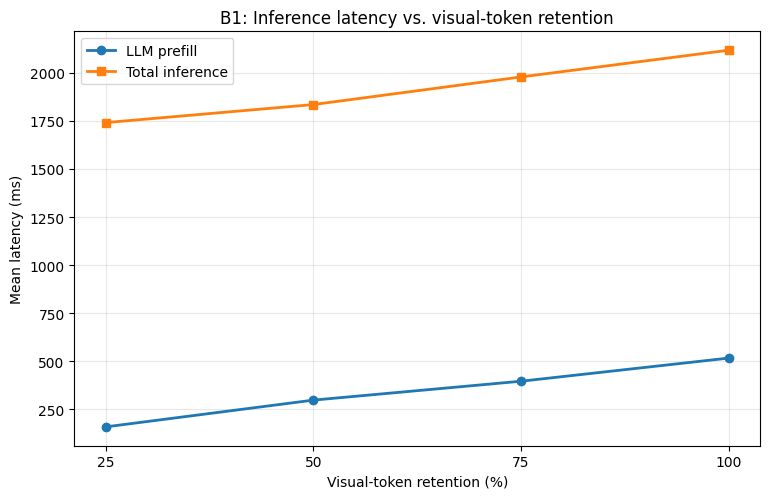

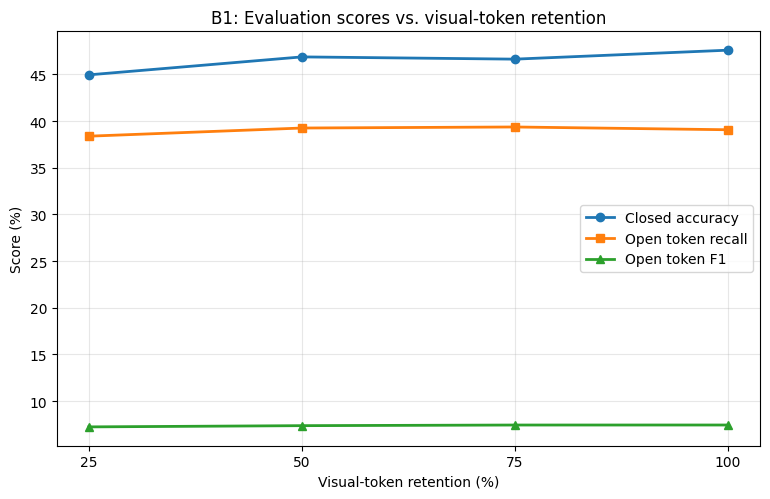

Latency figure: /kaggle/working/B1_LLaVA_Med/final_results/b1_latency_vs_retention.png
Accuracy figure: /kaggle/working/B1_LLaVA_Med/final_results/b1_accuracy_vs_retention.png

CELL 21 PASSED — FOUR-CONDITION B1 COMPARISON COMPLETE


In [28]:

# ============================================================
# B1 — CELL 21: FINAL COMPARISON AND INTEGRITY AUDIT
# 100%, 75%, 50%, 25% visual-token retention
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
OUT = ROOT / "final_results"
OUT.mkdir(parents=True, exist_ok=True)

RETENTIONS = [100, 75, 50, 25]
EXPECTED_COUNTS = {100: 576, 75: 432, 50: 288, 25: 144}

print("=" * 72)
print("B1 — CELL 21: FINAL EXPERIMENT COMPARISON")
print("=" * 72)

# ------------------------------------------------------------
# 1. Read all four experiments
# ------------------------------------------------------------
print("\n[1] LOAD AND VALIDATE EXPERIMENTS")

datasets = {}
configurations = {}

for pct in RETENTIONS:
    path = ROOT / f"predictions/b1_{pct}pct_predictions.jsonl"
    config_path = ROOT / f"configs/b1_{pct}pct_run_config.json"

    assert path.is_file(), f"Missing {path}"
    assert config_path.is_file(), f"Missing {config_path}"

    with open(path, encoding="utf-8") as f:
        records = [
            json.loads(line) for line in f if line.strip()
        ]

    with open(config_path, encoding="utf-8") as f:
        configurations[pct] = json.load(f)

    by_qid = {str(r["qid"]): r for r in records}

    assert len(records) == 1061
    assert len(by_qid) == 1061
    assert all(r["retention_pct"] == pct for r in records)
    assert all(
        r["retained_visual_tokens"] == EXPECTED_COUNTS[pct]
        for r in records
    )

    datasets[pct] = by_qid
    print(f"B1-{pct}: {len(records)} unique questions — PASS")

baseline_ids = set(datasets[100])

for pct in RETENTIONS[1:]:
    assert set(datasets[pct]) == baseline_ids, (
        f"Question IDs differ for B1-{pct}"
    )

# Check experiment configs match except for retention.
reference_config = {
    k: v
    for k, v in configurations[100].items()
    if k != "retention_pct"
}

for pct in RETENTIONS[1:]:
    other = {
        k: v
        for k, v in configurations[pct].items()
        if k != "retention_pct"
    }
    assert other == reference_config, (
        f"Experiment config mismatch for B1-{pct}"
    )

print("All four question-ID sets: IDENTICAL")
print("All non-retention settings: IDENTICAL")

# ------------------------------------------------------------
# 2. Verify question alignment and collect paired records
# ------------------------------------------------------------
print("\n[2] QUESTION-LEVEL CONSISTENCY")

combined_rows = []

for qid in sorted(
    baseline_ids,
    key=lambda x: int(x) if x.isdigit() else x
):
    baseline = datasets[100][qid]

    for pct in RETENTIONS:
        r = datasets[pct][qid]

        for key in (
            "question", "reference", "answer_type",
            "img_name", "original_test_index"
        ):
            assert r[key] == baseline[key], (
                f"Mismatch QID={qid}, retention={pct}, field={key}"
            )

        p = r["profiling"]
        s = r["scoring"]

        combined_rows.append({
            "qid": qid,
            "retention_pct": pct,
            "visual_tokens": EXPECTED_COUNTS[pct],
            "answer_type": r["answer_type"],
            "question": r["question"],
            "reference": r["reference"],
            "prediction": r["prediction"],
            "closed_scoring_method": s["closed_scoring_method"],
            "closed_accuracy": s["closed_accuracy"],
            "open_precision": s["open_precision"],
            "open_recall": s["open_recall"],
            "open_f1": s["open_f1"],
            "prefill_ms": p["llm_prefill_ms"],
            "vision_ms": p["vision_encoding_ms"],
            "decode_forward_ms": p["decoding_forward_ms"],
            "total_inference_ms": p["total_inference_ms"],
            "gpu_memory_sum_gib": p["peak_memory_sum_gib"],
            "gpu_memory_max_device_gib": p[
                "peak_memory_max_device_gib"
            ],
            "generated_tokens": r["generated_tokens"],
            "eos_terminated": r["eos_terminated"],
            "reached_generation_limit": r[
                "reached_generation_limit"
            ]
        })

df = pd.DataFrame(combined_rows)

assert len(df) == 1061 * 4
assert not df["prediction"].str.strip().eq("").any()
assert (df["prefill_ms"] > 0).all()
assert (df["total_inference_ms"] > 0).all()

print("Total records:", len(df))
print("Unique questions:", df["qid"].nunique())
print("Answer/reference alignment: PASS")
print("Nonempty predictions: PASS")

# ------------------------------------------------------------
# 3. Aggregate experimental results
# ------------------------------------------------------------
print("\n[3] AGGREGATE METRICS")

summary_rows = []

for pct in RETENTIONS:
    part = df[df["retention_pct"] == pct]

    closed = part[part["answer_type"] == "closed"]
    opened = part[part["answer_type"] == "open"]

    yesno = closed[
        closed["closed_scoring_method"] == "yes_no_extraction"
    ]
    categorical = closed[
        closed["closed_scoring_method"] == "categorical_exact_match"
    ]

    assert len(part) == 1061
    assert len(closed) == 416
    assert len(opened) == 645
    assert len(yesno) == 355
    assert len(categorical) == 61

    summary_rows.append({
        "retention_pct": pct,
        "visual_tokens": EXPECTED_COUNTS[pct],
        "questions": len(part),
        "closed_accuracy_pct": closed["closed_accuracy"].mean() * 100,
        "yesno_accuracy_pct": yesno["closed_accuracy"].mean() * 100,
        "categorical_accuracy_pct": (
            categorical["closed_accuracy"].mean() * 100
        ),
        "open_recall_pct": opened["open_recall"].mean() * 100,
        "open_f1_pct": opened["open_f1"].mean() * 100,
        "mean_prefill_ms": part["prefill_ms"].mean(),
        "median_prefill_ms": part["prefill_ms"].median(),
        "mean_vision_ms": part["vision_ms"].mean(),
        "mean_total_ms": part["total_inference_ms"].mean(),
        "p95_total_ms": part["total_inference_ms"].quantile(0.95),
        "mean_generated_tokens": part["generated_tokens"].mean(),
        "mean_gpu_allocation_gib": (
            part["gpu_memory_sum_gib"].mean()
        ),
        "max_gpu_allocation_gib": (
            part["gpu_memory_sum_gib"].max()
        ),
        "generation_limit_cases": int(
            part["reached_generation_limit"].sum()
        )
    })

summary_df = pd.DataFrame(summary_rows)

baseline = summary_df.iloc[0]

summary_df["prefill_reduction_pct"] = (
    1 - summary_df["mean_prefill_ms"]
    / baseline["mean_prefill_ms"]
) * 100

summary_df["total_latency_reduction_pct"] = (
    1 - summary_df["mean_total_ms"]
    / baseline["mean_total_ms"]
) * 100

summary_df["prefill_speedup_x"] = (
    baseline["mean_prefill_ms"]
    / summary_df["mean_prefill_ms"]
)

summary_df["closed_accuracy_delta_pp"] = (
    summary_df["closed_accuracy_pct"]
    - baseline["closed_accuracy_pct"]
)

summary_df["open_f1_delta_pp"] = (
    summary_df["open_f1_pct"]
    - baseline["open_f1_pct"]
)

display_columns = [
    "retention_pct",
    "visual_tokens",
    "closed_accuracy_pct",
    "open_recall_pct",
    "open_f1_pct",
    "mean_prefill_ms",
    "mean_total_ms",
    "mean_gpu_allocation_gib",
    "prefill_reduction_pct",
    "total_latency_reduction_pct",
    "closed_accuracy_delta_pp"
]

print(
    summary_df[display_columns]
    .round(3)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 4. Paired question-level comparison
# ------------------------------------------------------------
print("\n[4] PAIRED COMPARISON AGAINST B1-100")

baseline_predictions = {
    qid: datasets[100][qid]["prediction"]
    for qid in baseline_ids
}

for pct in RETENTIONS[1:]:
    changed = sum(
        datasets[pct][qid]["prediction"]
        != baseline_predictions[qid]
        for qid in baseline_ids
    )

    print(
        f"B1-{pct}: {changed}/1061 predictions differ "
        f"from B1-100 ({changed / 1061 * 100:.2f}%)"
    )

# ------------------------------------------------------------
# 5. Save consolidated tables
# ------------------------------------------------------------
print("\n[5] SAVE RESULTS")

detail_path = OUT / "b1_all_predictions_and_metrics.csv"
summary_path = OUT / "b1_summary.csv"
summary_json = OUT / "b1_summary.json"

df.to_csv(detail_path, index=False)
summary_df.to_csv(summary_path, index=False)

with open(summary_json, "w", encoding="utf-8") as f:
    json.dump(
        summary_df.to_dict(orient="records"),
        f,
        indent=2
    )

print("Detailed records:", detail_path)
print("Summary CSV:", summary_path)
print("Summary JSON:", summary_json)

# ------------------------------------------------------------
# 6. Figure 1: Latency versus retention
# ------------------------------------------------------------
print("\n[6] CREATE FIGURES")

x = summary_df["retention_pct"].to_numpy()

plt.figure(figsize=(7.8, 5.1))
plt.plot(
    x,
    summary_df["mean_prefill_ms"],
    marker="o",
    linewidth=2,
    label="LLM prefill"
)
plt.plot(
    x,
    summary_df["mean_total_ms"],
    marker="s",
    linewidth=2,
    label="Total inference"
)

plt.xlabel("Visual-token retention (%)")
plt.ylabel("Mean latency (ms)")
plt.title("B1: Inference latency vs. visual-token retention")
plt.xticks([25, 50, 75, 100])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

latency_plot = OUT / "b1_latency_vs_retention.png"
plt.savefig(latency_plot, dpi=220)
plt.show()
plt.close()

# ------------------------------------------------------------
# 7. Figure 2: Accuracy versus retention
# ------------------------------------------------------------
plt.figure(figsize=(7.8, 5.1))
plt.plot(
    x,
    summary_df["closed_accuracy_pct"],
    marker="o",
    linewidth=2,
    label="Closed accuracy"
)
plt.plot(
    x,
    summary_df["open_recall_pct"],
    marker="s",
    linewidth=2,
    label="Open token recall"
)
plt.plot(
    x,
    summary_df["open_f1_pct"],
    marker="^",
    linewidth=2,
    label="Open token F1"
)

plt.xlabel("Visual-token retention (%)")
plt.ylabel("Score (%)")
plt.title("B1: Evaluation scores vs. visual-token retention")
plt.xticks([25, 50, 75, 100])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

accuracy_plot = OUT / "b1_accuracy_vs_retention.png"
plt.savefig(accuracy_plot, dpi=220)
plt.show()
plt.close()

print("Latency figure:", latency_plot)
print("Accuracy figure:", accuracy_plot)

print("\n" + "=" * 72)
print("CELL 21 PASSED — FOUR-CONDITION B1 COMPARISON COMPLETE")
print("=" * 72)


# Analysis: Extra

In [29]:

# ============================================================
# B1 — CELL 22: PAIRED STATISTICAL ANALYSIS
# + CATEGORICAL ANSWER AUDIT
# No model loading or GPU required
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import binomtest

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
OUT = ROOT / "final_results"
DATA = OUT / "b1_all_predictions_and_metrics.csv"

assert DATA.is_file(), "Run Cell 21 first."

df = pd.read_csv(DATA, dtype={"qid": str})
RETENTIONS = [100, 75, 50, 25]

print("=" * 72)
print("B1 — CELL 22: PAIRED STATISTICAL ANALYSIS")
print("=" * 72)

assert len(df) == 4244
assert df["qid"].nunique() == 1061

# ------------------------------------------------------------
# 1. Align identical questions across retention conditions
# ------------------------------------------------------------
print("\n[1] PAIRED ALIGNMENT")

closed = df[df["answer_type"] == "closed"].copy()
opened = df[df["answer_type"] == "open"].copy()

closed_matrix = closed.pivot(
    index="qid",
    columns="retention_pct",
    values="closed_accuracy"
)[RETENTIONS].astype(float)

open_f1_matrix = opened.pivot(
    index="qid",
    columns="retention_pct",
    values="open_f1"
)[RETENTIONS].astype(float)

open_recall_matrix = opened.pivot(
    index="qid",
    columns="retention_pct",
    values="open_recall"
)[RETENTIONS].astype(float)

assert closed_matrix.shape == (416, 4)
assert open_f1_matrix.shape == (645, 4)
assert open_recall_matrix.shape == (645, 4)

assert not closed_matrix.isna().any().any()
assert not open_f1_matrix.isna().any().any()

print("Closed questions aligned:", len(closed_matrix))
print("Open questions aligned:", len(open_f1_matrix))

# ------------------------------------------------------------
# 2. Paired bootstrap confidence intervals
# ------------------------------------------------------------
rng = np.random.default_rng(42)
N_BOOTSTRAP = 5000

def bootstrap_mean_difference(baseline, candidate):
    difference = (
        np.asarray(candidate, dtype=float)
        - np.asarray(baseline, dtype=float)
    )

    n = len(difference)

    sampled_indices = rng.integers(
        low=0,
        high=n,
        size=(N_BOOTSTRAP, n)
    )

    bootstrap_means = difference[sampled_indices].mean(axis=1)

    ci_low, ci_high = np.quantile(
        bootstrap_means, [0.025, 0.975]
    )

    return {
        "mean_delta": float(difference.mean()),
        "ci_low": float(ci_low),
        "ci_high": float(ci_high)
    }

# ------------------------------------------------------------
# 3. Exact paired test for closed accuracy
# ------------------------------------------------------------
def mcnemar_exact(baseline, candidate):
    baseline = np.asarray(baseline, dtype=int)
    candidate = np.asarray(candidate, dtype=int)

    # Model was correct at 100% but incorrect after pruning.
    lost = int(((baseline == 1) & (candidate == 0)).sum())

    # Model was incorrect at 100% but correct after pruning.
    gained = int(((baseline == 0) & (candidate == 1)).sum())

    discordant = lost + gained

    p_value = (
        float(binomtest(
            min(lost, gained),
            discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue)
        if discordant else 1.0
    )

    return lost, gained, discordant, p_value

print("\n[2] CLOSED ACCURACY — PAIRED ANALYSIS")

statistical_rows = []

for pct in [75, 50, 25]:

    base_closed = closed_matrix[100].to_numpy()
    test_closed = closed_matrix[pct].to_numpy()

    delta_closed = bootstrap_mean_difference(
        base_closed, test_closed
    )

    lost, gained, discordant, p = mcnemar_exact(
        base_closed, test_closed
    )

    delta_f1 = bootstrap_mean_difference(
        open_f1_matrix[100].to_numpy(),
        open_f1_matrix[pct].to_numpy()
    )

    delta_recall = bootstrap_mean_difference(
        open_recall_matrix[100].to_numpy(),
        open_recall_matrix[pct].to_numpy()
    )

    statistical_rows.append({
        "retention_pct": pct,
        "closed_accuracy_delta_pp":
            delta_closed["mean_delta"] * 100,
        "closed_ci_low_pp":
            delta_closed["ci_low"] * 100,
        "closed_ci_high_pp":
            delta_closed["ci_high"] * 100,
        "closed_lost_correct": lost,
        "closed_gained_correct": gained,
        "closed_discordant": discordant,
        "mcnemar_exact_p": p,
        "open_f1_delta_pp":
            delta_f1["mean_delta"] * 100,
        "open_f1_ci_low_pp":
            delta_f1["ci_low"] * 100,
        "open_f1_ci_high_pp":
            delta_f1["ci_high"] * 100,
        "open_recall_delta_pp":
            delta_recall["mean_delta"] * 100,
        "open_recall_ci_low_pp":
            delta_recall["ci_low"] * 100,
        "open_recall_ci_high_pp":
            delta_recall["ci_high"] * 100
    })

stats_df = pd.DataFrame(statistical_rows)

print(
    stats_df[[
        "retention_pct",
        "closed_accuracy_delta_pp",
        "closed_ci_low_pp",
        "closed_ci_high_pp",
        "closed_lost_correct",
        "closed_gained_correct",
        "mcnemar_exact_p",
        "open_f1_delta_pp",
        "open_f1_ci_low_pp",
        "open_f1_ci_high_pp"
    ]].round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 4. Investigate categorical closed answers
# ------------------------------------------------------------
print("\n[3] CATEGORICAL CLOSED-ANSWER AUDIT")

categorical = df[
    df["closed_scoring_method"] == "categorical_exact_match"
].copy()

assert len(categorical) == 61 * 4

for pct in RETENTIONS:
    subset = categorical[
        categorical["retention_pct"] == pct
    ]

    exact_correct = int(
        (subset["closed_accuracy"] == 1).sum()
    )

    print(
        f"B1-{pct}: "
        f"exact matches = {exact_correct}/61"
    )

print("\nExample categorical predictions at 100%:")

examples = categorical[
    categorical["retention_pct"] == 100
].head(10)

for _, row in examples.iterrows():
    print("\nQID:", row["qid"])
    print("Question:", row["question"])
    print("Reference:", row["reference"])
    print("Prediction:", str(row["prediction"])[:300])

# ------------------------------------------------------------
# 5. Answer-length and truncation analysis
# ------------------------------------------------------------
print("\n[4] GENERATION LENGTH AND TRUNCATION")

length_summary = df.groupby("retention_pct").agg(
    mean_generated_tokens=("generated_tokens", "mean"),
    median_generated_tokens=("generated_tokens", "median"),
    max_generated_tokens=("generated_tokens", "max"),
    generation_limit_cases=("reached_generation_limit", "sum")
).reindex(RETENTIONS)

print(length_summary.round(3).to_string())

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------
print("\n[5] SAVE ANALYSIS")

stats_path = OUT / "b1_paired_statistical_analysis.csv"
categorical_path = OUT / "b1_categorical_answer_audit.csv"
length_path = OUT / "b1_generation_length_analysis.csv"

stats_df.to_csv(stats_path, index=False)
categorical.to_csv(categorical_path, index=False)
length_summary.to_csv(length_path)

print("Statistical analysis:", stats_path)
print("Categorical audit:", categorical_path)
print("Generation analysis:", length_path)

print("\n" + "=" * 72)
print("CELL 22 PASSED — PAIRED ANALYSIS COMPLETE")
print("=" * 72)


B1 — CELL 22: PAIRED STATISTICAL ANALYSIS

[1] PAIRED ALIGNMENT
Closed questions aligned: 416
Open questions aligned: 645

[2] CLOSED ACCURACY — PAIRED ANALYSIS
 retention_pct  closed_accuracy_delta_pp  closed_ci_low_pp  closed_ci_high_pp  closed_lost_correct  closed_gained_correct  mcnemar_exact_p  open_f1_delta_pp  open_f1_ci_low_pp  open_f1_ci_high_pp
            75                   -0.9615           -1.9231            -0.2404                    4                      0           0.1250           -0.0022            -0.2066              0.2050
            50                   -0.7212           -2.4038             0.7212                    7                      4           0.5488           -0.0700            -0.3042              0.1661
            25                   -2.6442           -4.8077            -0.4808                   15                      4           0.0192           -0.2016            -0.5292              0.1285

[3] CATEGORICAL CLOSED-ANSWER AUDIT
B1-100: exact matc

In [30]:

# ============================================================
# B1 — CELL 23: CATEGORICAL ANSWER PATTERN ANALYSIS
# No GPU / no model inference
# ============================================================

import pandas as pd
from pathlib import Path
from statsmodels.stats.multitest import multipletests

ROOT = Path("/kaggle/working/B1_LLaVA_Med")
OUT = ROOT / "final_results"

df = pd.read_csv(
    OUT / "b1_all_predictions_and_metrics.csv",
    dtype={"qid": str}
)

categorical = df[
    df["closed_scoring_method"] == "categorical_exact_match"
].copy()

baseline = categorical[
    categorical["retention_pct"] == 100
].copy()

print("=" * 72)
print("B1 — CELL 23: CATEGORICAL ANSWER ANALYSIS")
print("=" * 72)

# ------------------------------------------------------------
# 1. Dataset structure
# ------------------------------------------------------------
print("\n[1] CATEGORICAL QUESTION STRUCTURE")

assert len(baseline) == 61
assert len(categorical) == 244

print("Categorical questions:", len(baseline))
print("Unique question texts:", baseline["question"].nunique())
print("Unique reference answers:", baseline["reference"].nunique())

print("\nReference answer frequencies:")
print(
    baseline["reference"]
    .value_counts()
    .to_string()
)

# ------------------------------------------------------------
# 2. Unique question patterns
# ------------------------------------------------------------
print("\n[2] UNIQUE CATEGORICAL QUESTION PATTERNS")

patterns = (
    baseline.groupby("question")
    .agg(
        n=("qid", "count"),
        answers=("reference", lambda x: sorted(set(x)))
    )
    .reset_index()
    .sort_values("n", ascending=False)
)

for _, row in patterns.iterrows():
    print("\nQuestion:", row["question"])
    print("Count:", row["n"])
    print("Reference choices:", row["answers"])

# ------------------------------------------------------------
# 3. Examples for every question pattern
# ------------------------------------------------------------
print("\n[3] MODEL RESPONSE EXAMPLES")

for question, group in baseline.groupby("question"):

    print("\n" + "-" * 72)
    print("QUESTION:", question)

    for _, r in group.head(3).iterrows():
        print("\nQID:", r["qid"])
        print("Reference:", r["reference"])
        print("Prediction:", r["prediction"])

# ------------------------------------------------------------
# 4. Prediction stability under retention
# ------------------------------------------------------------
print("\n[4] CATEGORICAL PREDICTION STABILITY")

pivot = categorical.pivot(
    index="qid",
    columns="retention_pct",
    values="prediction"
)

for pct in [75, 50, 25]:
    changed = int(
        (pivot[pct] != pivot[100]).sum()
    )
    print(
        f"B1-{pct}: {changed}/61 "
        f"categorical predictions changed"
    )

# ------------------------------------------------------------
# 5. Holm adjustment for previous paired tests
# ------------------------------------------------------------
print("\n[5] MULTIPLE-COMPARISON ADJUSTMENT")

stats = pd.read_csv(
    OUT / "b1_paired_statistical_analysis.csv"
)

reject, adjusted, _, _ = multipletests(
    stats["mcnemar_exact_p"].to_numpy(),
    alpha=0.05,
    method="holm"
)

stats["mcnemar_holm_p"] = adjusted
stats["significant_holm_005"] = reject

print(
    stats[[
        "retention_pct",
        "mcnemar_exact_p",
        "mcnemar_holm_p",
        "significant_holm_005"
    ]].to_string(index=False)
)

# ------------------------------------------------------------
# 6. Save categorical audit
# ------------------------------------------------------------
print("\n[6] SAVE ANALYSIS")

patterns_path = OUT / "b1_categorical_question_patterns.csv"
adjusted_path = OUT / "b1_paired_statistics_holm.csv"

patterns.to_csv(patterns_path, index=False)
stats.to_csv(adjusted_path, index=False)

print("Question patterns:", patterns_path)
print("Adjusted statistics:", adjusted_path)

print("\n" + "=" * 72)
print("CELL 23 PASSED — CATEGORICAL PATTERNS IDENTIFIED")
print("=" * 72)


B1 — CELL 23: CATEGORICAL ANSWER ANALYSIS

[1] CATEGORICAL QUESTION STRUCTURE
Categorical questions: 61
Unique question texts: 31
Unique reference answers: 18

Reference answer frequencies:
reference
Lung             12
Liver             9
T2                7
Heart             5
Right             4
Spleen            3
Left              3
Coronal Plane     3
Hyperdense        3
T1                2
Esophagus         2
Colon             2
CT                1
Right Kidney      1
Kidney            1
Top               1
Rectum            1
Small Bowel       1

[2] UNIQUE CATEGORICAL QUESTION PATTERNS

Question: Which organ is abnormal, heart or lung?
Count: 11
Reference choices: ['Heart', 'Lung']

Question: Which kind of weighting is this image generated with, t1 or t2?
Count: 6
Reference choices: ['T1', 'T2']

Question: Which is the biggest in this image,lung,liver or heart?
Count: 5
Reference choices: ['Liver', 'Lung']

Question: Which side of lung is abnormal in this image,left or right?
